Mathematical Formulation
Sets:

- $  N  $: Set of selected high-priority customers (after pre-processing)
- $  N_0 = N \cup \{0\}  $: Set of all nodes, where 0 is the depot
- $  K = \{1, 2, \dots, m\}  $: Set of homogeneous drones

Parameters:

- $  d_{ij}  $: Euclidean distance between nodes $  i  $ and $  j  $
- $  e_{ij}  $: Energy consumption for traveling from $  i  $ to $  j  $
- $  q_i  $: Demand (payload) of customer $  i \in N  $
- $  p_i  $: Profit/urgency score of customer $  i  $ (used in pre-processing)
- $  B  $: Initial battery capacity of each drone (one charge per drone per day)
- $  Q  $: Maximum payload capacity of each drone
- $  M  $: Sufficiently large constant (Big-M)
- $  \lambda  $: Small positive weight for the secondary objective (energy minimization)

Decision Variables:

- $  x_{ijk} \in \{0,1\}  $: Binary variable equal to 1 if drone $  k  $ travels directly from node $  i  $ to node $  j  $
- $  u_{ik} \geq 0  $: Cumulative payload carried by drone $  k  $ upon arrival at node $  i  $
- $  b_{ik} \geq 0  $: Remaining battery of drone $  k  $ upon arrival at node $  i  $

Objective Function:
$$\max \quad \sum_{i \in N} p_i \ - \ \lambda \sum_{k \in K} \sum_{i \in N_0} \sum_{j \in N_0} e_{ij} \, x_{ijk}$$

Constraints
1. Each Customer in $  N  $ Served Exactly Once (Updated according to your pre-processing)
$$\sum_{k \in K} \sum_{j \in N_0} x_{ijk} = 1 \quad \forall i \in N$$
2. Flow Conservation
$$\sum_{i \in N_0} x_{ijk} = \sum_{j \in N_0} x_{jik} \quad \forall j \in N_0, \ \forall k \in K$$

3. Battery Constraints (One single charge per drone per day – No recharging)

Initial battery at the beginning:$$b_{0k} = B \quad \forall k \in K$$
Battery consumption on each arc:$$b_{ik} - e_{ij} \cdot x_{ijk} \geq b_{jk} - M(1 - x_{ijk}) \quad \forall i,j \in N_0, \ \forall k \in K$$
Battery limits:$$0 \leq b_{ik} \leq B \quad \forall i \in N_0, \ \forall k \in K$$

4. Payload Constraints (Delivery with unloading at customers + reloading at depot)

Payload update (delivery style):$$u_{ik} - q_j \geq u_{jk} - M(1 - x_{ijk}) \quad \forall i \in N_0, \ j \in N, \ \forall k \in K$$
Payload capacity limit:$$0 \leq u_{ik} \leq Q \quad \forall i \in N_0, \ \forall k \in K$$
Payload reset when returning to depot (reload):$$u_{0k} = 0 \quad \forall k \in K$$

5. Variable Domains

- $  x_{ijk} \in \{0,1\}  $
- $  u_{ik} \geq 0  $, $  b_{ik} \geq 0  $

In [125]:
import numpy as np
import pandas as pd
from pulp import *
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Tuple, Optional
import time
import copy
from collections import deque
import warnings
warnings.filterwarnings('ignore')
 
# Set random seed for reproducibility
np.random.seed(42)
 
# Plotting configuration
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")


In [126]:
class ProblemConfig:
    """Configuration class for drone delivery problem parameters"""
    
    def __init__(self):
        # Fleet parameters
        self.num_drones = 2  # Number of available drones (m)
        self.battery_capacity = 100.0  # Battery capacity B (energy units)
        self.payload_capacity = 10.0  # Payload capacity Q (kg)
        
        # Energy model parameters (Dorling et al. 2016 linear model)
        self.alpha = 0.5  # Energy per kg per km (Wh/kg/km)
        self.beta = 2.0   # Base energy per km (Wh/km)
        self.drone_mass = 3.0  # Base drone mass (kg)
        self.battery_mass = 1.0  # Battery mass (kg)
        
        # TOP parameters
        self.lambda_weight = 0.05  # Weight for energy penalty in objective
        
        # Multi-trip parameters
        self.max_trips_per_drone = 3  # Maximum trips per drone
        
        # Branch & Bound parameters
        self.bnb_time_limit = 300  # seconds (5 minutes)
        self.bnb_gap_tolerance = 0.05  # 5% optimality gap

        # Circles in the same coordinate system as customer locations (km).
        # IMPORTANT: For the default 50x50 area the depot is at (25, 25). Do not place a
        # zone centered on the depot with large radius: the naive arc test treats any
        # endpoint inside the disk as a blocked arc, which forbids ALL depot ↔ customer
        # legs and makes the MILP infeasible once those arcs are fixed to x == 0.
        self.no_fly_zones = [
            (38.0, 38.0, 7.0),
            (12.0, 12.0, 5.5),
            (40.0, 12.0, 6.0),
        ]
        
    def energy_consumption(self, distance: float, payload_mass: float) -> float:
        """
        Calculate energy consumption using linear model
        E_ij = (α * m_total + β) * d_ij
        
        Args:
            distance: Distance traveled (km)
            payload_mass: Current payload mass (kg)
            
        Returns:
            Energy consumed (Wh)
        """
        total_mass = self.drone_mass + self.battery_mass + payload_mass
        return (self.alpha * total_mass + self.beta) * distance
    
    def __repr__(self):
        return f"ProblemConfig(drones={self.num_drones}, B={self.battery_capacity}, Q={self.payload_capacity})"

In [127]:
config = ProblemConfig()
print(f"✓ Problem configuration created: {config}")

✓ Problem configuration created: ProblemConfig(drones=2, B=100.0, Q=10.0)


In [128]:
class InstanceGenerator:
    """Generate drone delivery problem instances"""
    
    def __init__(self, config: ProblemConfig):
        self.config = config
        
    def generate_instance(self, 
                         num_customers: int,
                         area_size: Tuple[float, float] = (50, 50),
                         urgency_distribution: str = 'mixed') -> Dict:
        """
        Generate a problem instance
        
        Args:
            num_customers: Number of customers to generate
            area_size: (width, height) of service area in km
            urgency_distribution: 'uniform', 'high_priority', or 'mixed'
            
        Returns:
            Dictionary containing instance data
        """
        # Generate depot at center
        depot_x = area_size[0] / 2
        depot_y = area_size[1] / 2
        
        # Generate customer locations (avoid depot vicinity) AND ensure battery-feasible round trip
        # This is required if later you enforce "all selected customers must be served" under battery B.
        customers_x = []
        customers_y = []

        # Conservative payload used for reachability screening (helps avoid generating impossible instances)
        payload_screen = 0.6 * self.config.payload_capacity

        for _ in range(num_customers):
            attempts = 0
            while True:
                attempts += 1
                if attempts > 5000:
                    raise RuntimeError(
                        "Could not generate battery-feasible customers. Increase B, reduce area_size, or relax screening."
                    )

                x = np.random.uniform(0, area_size[0])
                y = np.random.uniform(0, area_size[1])

                # Ensure minimum distance from depot (2 km)
                dist_to_depot = np.sqrt((x - depot_x) ** 2 + (y - depot_y) ** 2)
                if dist_to_depot <= 2.0:
                    continue

                # Battery-feasible necessary condition: depot -> customer -> depot within one charge
                e_out = self.config.energy_consumption(dist_to_depot, payload_screen)
                e_back = self.config.energy_consumption(dist_to_depot, payload_screen)
                if e_out + e_back > self.config.battery_capacity:
                    continue

                customers_x.append(x)
                customers_y.append(y)
                break
        
        # Generate demands (package weights) - realistic distribution
        # Most packages are 1-5 kg, some heavier ones
        demands = np.random.gamma(shape=2.0, scale=1.5, size=num_customers)
        demands = np.clip(demands, 0.5, 8.0)  # Between 0.5 and 8 kg
        
        # Generate urgency/profit scores based on distribution
        if urgency_distribution == 'uniform':
            urgencies = np.random.uniform(1, 10, num_customers)
        elif urgency_distribution == 'high_priority':
            # More high-urgency customers (medicine, urgent packages)
            urgencies = np.random.choice([8, 9, 10], size=num_customers, p=[0.3, 0.4, 0.3])
            # Add some medium priority
            mask = np.random.rand(num_customers) < 0.3
            urgencies[mask] = np.random.uniform(4, 7, mask.sum())
        else:  # mixed
            # Realistic distribution: few very urgent, many medium, some low
            urgencies = np.random.choice(
                [10, 9, 8, 6, 5, 3],
                size=num_customers,
                p=[0.1, 0.15, 0.2, 0.3, 0.15, 0.1]
            )
        
        # Calculate distance matrix (Euclidean)
        n = num_customers
        all_x = [depot_x] + customers_x
        all_y = [depot_y] + customers_y

        distance_matrix = np.zeros((n + 1, n + 1))
        energy_matrix = np.zeros((n + 1, n + 1))
        feasible_arc = np.ones((n + 1, n + 1), dtype=bool)   # True = allowed

        avg_payload = np.mean(demands)


        for i in range(n + 1):
            for j in range(n + 1):
                if i == j:
                    continue

                dist = np.sqrt((all_x[i] - all_x[j])**2 + (all_y[i] - all_y[j])**2)
                distance_matrix[i, j] = dist
                    

                # Check if this arc intersects any no-fly zone
                if self.intersects_no_fly_zone(all_x[i], all_y[i], all_x[j], all_y[j]):
                    feasible_arc[i, j] = False
                    energy_matrix[i, j] = 0
                else:
                    energy_matrix[i, j] = self.config.energy_consumption(
                        dist, avg_payload * 0.6
                    )
        
    
        
        instance = {
            'num_customers': num_customers,
            'depot': (depot_x, depot_y),
            'customers': list(zip(customers_x, customers_y)),
            'demands': demands.tolist(),
            'urgencies': urgencies.tolist(),
            'distance_matrix': distance_matrix,
            'energy_matrix': energy_matrix,
            'feasible_arc': feasible_arc,
            'area_size': area_size
        }
        
        return instance

    def intersects_no_fly_zone(self, x1: float, y1: float, x2: float, y2: float) -> bool:
        """True if the closed segment (x1,y1)-(x2,y2) meets any circular no-fly disk."""

        def segment_hits_disk(ax, ay, bx, by, cx, cy, r) -> bool:
            r2 = r * r
            if (ax - cx) ** 2 + (ay - cy) ** 2 <= r2:
                return True
            if (bx - cx) ** 2 + (by - cy) ** 2 <= r2:
                return True
            dx, dy = bx - ax, by - ay
            if dx == 0 and dy == 0:
                return False
            t = ((cx - ax) * dx + (cy - ay) * dy) / (dx * dx + dy * dy)
            t = max(0.0, min(1.0, t))
            px, py = ax + t * dx, ay + t * dy
            return (px - cx) ** 2 + (py - cy) ** 2 <= r2

        for cx, cy, radius in self.config.no_fly_zones:
            if segment_hits_disk(x1, y1, x2, y2, cx, cy, radius):
                return True
        return False

    
    def visualize_instance(self, instance: Dict, title: str = "Instance Visualization"):
        """Visualize the generated instance"""
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
        
        # Plot 1: Locations with urgency
        depot = instance['depot']
        customers = instance['customers']
        urgencies = instance['urgencies']
        demands = instance['demands']
        
        # Plot depot
        ax1.scatter([depot[0]], [depot[1]], c='red', s=300, marker='s', 
                   label='Depot', edgecolors='black', linewidths=2, zorder=5)
        
        # Plot customers with urgency coloring
        scatter = ax1.scatter(
            [c[0] for c in customers],
            [c[1] for c in customers],
            c=urgencies,
            s=[d * 30 for d in demands],  # Size proportional to demand
            cmap='YlOrRd',
            alpha=0.7,
            edgecolors='black',
            linewidths=1,
            zorder=3
        )
        
        # Add customer labels
        for i, (x, y) in enumerate(customers):
            ax1.annotate(f'{i+1}', (x, y), fontsize=8, ha='center', va='center')
        
        ax1.set_xlabel('X coordinate (km)')
        ax1.set_ylabel('Y coordinate (km)')
        ax1.set_title(f'{title}\n(Size ∝ Demand, Color ∝ Urgency)')
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        cbar = plt.colorbar(scatter, ax=ax1)
        cbar.set_label('Urgency Score')
        
        # Plot 2: Customer characteristics
        customer_ids = list(range(1, instance['num_customers'] + 1))
        
        ax2_twin = ax2.twinx()
        
        bar1 = ax2.bar(customer_ids, urgencies, alpha=0.6, color='orange', label='Urgency')
        bar2 = ax2_twin.bar([x + 0.3 for x in customer_ids], demands, 
                           width=0.3, alpha=0.6, color='blue', label='Demand (kg)')
        
        ax2.set_xlabel('Customer ID')
        ax2.set_ylabel('Urgency Score', color='orange')
        ax2_twin.set_ylabel('Demand (kg)', color='blue')
        ax2.set_title('Customer Urgency and Demand')
        ax2.tick_params(axis='y', labelcolor='orange')
        ax2_twin.tick_params(axis='y', labelcolor='blue')
        ax2.grid(True, alpha=0.3)
        
        # Combine legends
        lines1, labels1 = ax2.get_legend_handles_labels()
        lines2, labels2 = ax2_twin.get_legend_handles_labels()
        ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right')
        
        plt.tight_layout()
        plt.show()
        
        # Print instance statistics
        print(f"\n{'='*60}")
        print(f"INSTANCE STATISTICS")
        print(f"{'='*60}")
        print(f"Number of customers: {instance['num_customers']}")
        print(f"Total demand: {sum(instance['demands']):.2f} kg")
        print(f"Average demand: {np.mean(instance['demands']):.2f} kg")
        print(f"Urgency range: [{min(urgencies)}, {max(urgencies)}]")
        print(f"Average urgency: {np.mean(urgencies):.2f}")
        print(f"Max distance from depot: {np.max(instance['distance_matrix'][0, 1:]):.2f} km")
        print(f"Min distance from depot: {np.min(instance['distance_matrix'][0, 1:]):.2f} km")
        print(f"{'='*60}\n")
 

In [129]:
generator = InstanceGenerator(config)
print("✓ Instance generator created")

✓ Instance generator created


Generating SMALL instance (5 customers)...


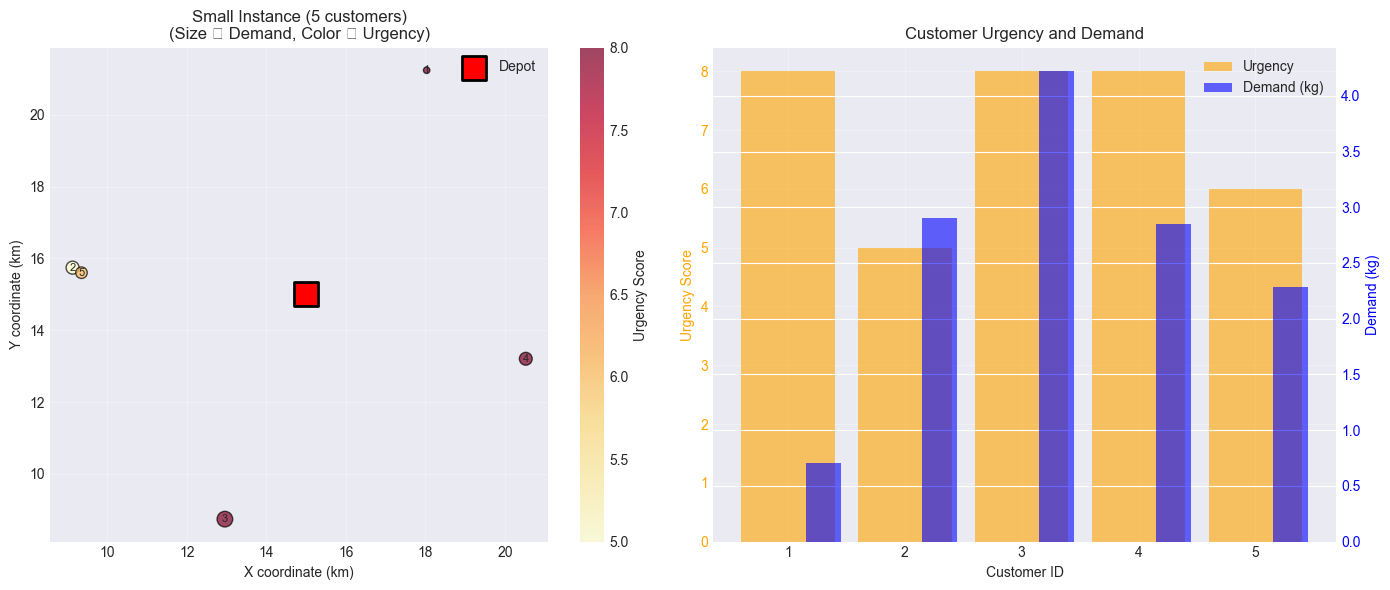


INSTANCE STATISTICS
Number of customers: 5
Total demand: 12.96 kg
Average demand: 2.59 kg
Urgency range: [5, 8]
Average urgency: 7.00
Max distance from depot: 6.94 km
Min distance from depot: 5.68 km


Generating MEDIUM instance (10 customers)...


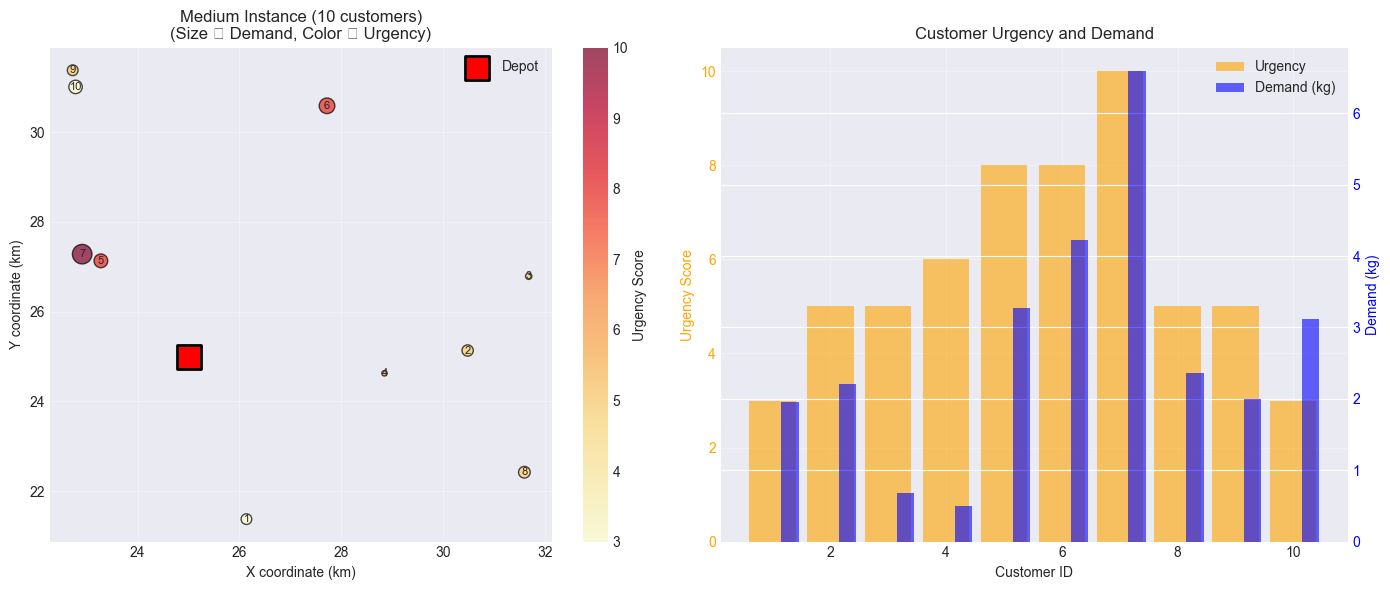


INSTANCE STATISTICS
Number of customers: 10
Total demand: 26.91 kg
Average demand: 2.69 kg
Urgency range: [3, 10]
Average urgency: 5.80
Max distance from depot: 7.08 km
Min distance from depot: 2.74 km


✓ Sample instances generated and stored


In [130]:
# Small instance for testing (5 customers)
print("Generating SMALL instance (5 customers)...")
small_instance = generator.generate_instance(
    num_customers=5,
    area_size=(30, 30),
    urgency_distribution='mixed'
)
generator.visualize_instance(small_instance, "Small Instance (5 customers)")
 
# Medium instance (10 customers)
print("\nGenerating MEDIUM instance (10 customers)...")
medium_instance = generator.generate_instance(
    num_customers=10,
    area_size=(50, 50),
    urgency_distribution='mixed'
)
generator.visualize_instance(medium_instance, "Medium Instance (10 customers)")
 
# Store instances for later use
instances = {
    'small': small_instance,
    'medium': medium_instance
}
 
print("\n✓ Sample instances generated and stored")

In [131]:
"""
Pre-processing step to select high-priority customers
Based on your TOP approach
"""
 
def preprocess_customer_selection(instance: Dict, 
                                  config: ProblemConfig,
                                  k_max: Optional[int] = None) -> Dict:
    """Select top-K customers by urgency **that are feasible to serve**.

    If you later enforce "serve all selected customers exactly once", then this preprocessing
    must remove customers that are individually infeasible (e.g., cannot do depot→i→depot within B).
    """
    n = instance['num_customers']
    urgencies = np.array(instance['urgencies'])
    demands = np.array(instance['demands'])
    e = instance['energy_matrix']
    B = config.battery_capacity
    Q = config.payload_capacity

    # Feasibility filter: each selected customer must at least be reachable in a single out-and-back trip
    # (necessary condition for any serve-all model with depot start/end).
    feasible_mask = np.array([(e[0, i+1] + e[i+1, 0] <= B) and (demands[i] <= Q) for i in range(n)])
    feasible_indices = np.where(feasible_mask)[0]

    if len(feasible_indices) == 0:
        raise ValueError("No customers are individually feasible under current B/Q (round-trip + demand).")

    # If k_max not specified, estimate based on resources
    if k_max is None:
        # crude upper bound based on payload and number of drones (single tour per drone)
        k_max = min(len(feasible_indices), max(1, int(config.num_drones * (Q / max(1e-9, np.mean(demands[feasible_indices]))))))

    # Sort feasible customers by urgency (descending) and pick top-k
    sorted_feasible = feasible_indices[np.argsort(-urgencies[feasible_indices])]
    selected_indices = sorted_feasible[:k_max]
    
    # Create filtered instance
    filtered_instance = copy.deepcopy(instance)
    filtered_instance['num_customers'] = len(selected_indices)
    filtered_instance['customers'] = [instance['customers'][i] for i in selected_indices]
    filtered_instance['demands'] = [instance['demands'][i] for i in selected_indices]
    filtered_instance['urgencies'] = [instance['urgencies'][i] for i in selected_indices]
    
    # Update matrices (keep depot as index 0, reindex customers)
    new_n = len(selected_indices)
    new_distance_matrix = np.zeros((new_n + 1, new_n + 1))
    new_energy_matrix = np.zeros((new_n + 1, new_n + 1))
    
    # Map old indices to new indices (depot remains 0)
    index_mapping = [0] + [i + 1 for i in selected_indices]
    
    for new_i in range(new_n + 1):
        for new_j in range(new_n + 1):
            old_i = index_mapping[new_i]
            old_j = index_mapping[new_j]
            new_distance_matrix[new_i, new_j] = instance['distance_matrix'][old_i, old_j]
            new_energy_matrix[new_i, new_j] = instance['energy_matrix'][old_i, old_j]

    old_fa = instance.get("feasible_arc")
    if old_fa is not None:
        old_fa = np.array(old_fa, dtype=bool)
        new_feasible = np.zeros((new_n + 1, new_n + 1), dtype=bool)
        for new_i in range(new_n + 1):
            for new_j in range(new_n + 1):
                if new_i == new_j:
                    continue
                oi = index_mapping[new_i]
                oj = index_mapping[new_j]
                new_feasible[new_i, new_j] = bool(old_fa[oi, oj])
        filtered_instance["feasible_arc"] = new_feasible
    
    filtered_instance['distance_matrix'] = new_distance_matrix
    filtered_instance['energy_matrix'] = new_energy_matrix
    filtered_instance['original_indices'] = selected_indices.tolist()
    filtered_instance['k_max'] = k_max
    
    print(f"\n{'='*60}")
    print(f"PREPROCESSING: Customer Selection (TOP Element)")
    print(f"{'='*60}")
    print(f"Original customers: {n}")
    print(f"Selected customers (K_max): {k_max}")
    print(f"Selection rate: {k_max/n*100:.1f}%")
    print(f"Selected customer IDs: {[i+1 for i in selected_indices]}")
    print(f"Total urgency of selected: {sum(filtered_instance['urgencies']):.1f}")
    print(f"Total urgency of all: {sum(instance['urgencies']):.1f}")
    print(f"Urgency captured: {sum(filtered_instance['urgencies'])/sum(instance['urgencies'])*100:.1f}%")
    print(f"{'='*60}\n")
    
    return filtered_instance
 
 

In [132]:
# Apply preprocessing to medium instance
preprocessed_medium = preprocess_customer_selection(medium_instance, config, k_max=7)
 
print("✓ Preprocessing complete")


PREPROCESSING: Customer Selection (TOP Element)
Original customers: 10
Selected customers (K_max): 7
Selection rate: 70.0%
Selected customer IDs: [np.int64(7), np.int64(5), np.int64(6), np.int64(4), np.int64(2), np.int64(3), np.int64(8)]
Total urgency of selected: 47.0
Total urgency of all: 58.0
Urgency captured: 81.0%

✓ Preprocessing complete


In [133]:
class DroneDeliveryMILP:
    """Arc-based MILP formulation for drone delivery problem"""
    
    def __init__(self, instance: Dict, config: ProblemConfig):
        self.instance = instance
        self.config = config
        self.n = instance['num_customers']  # Number of customers
        self.m = config.num_drones  # Number of drones
        self.model = None
        self.variables = {}
        
    def build_model(self):
        """Arc-Based MILP (serve-all selected customers) with multi-trip drones.

        We model each possible trip as its own vehicle: V = num_drones * max_trips_per_drone.
        Each trip starts/ends at the depot with a full battery, which matches the "no recharging mid-route"
        assumption while still allowing multiple depot returns per drone (across trips).
        """
        R = int(getattr(self.config, 'max_trips_per_drone', 1))
        V_count = self.m * R
        print(f"Building MILP model for {self.n} customers, {self.m} drones, up to {R} trips/drone (V={V_count})...")

        self.model = LpProblem("Drone_Delivery_Optimization", LpMinimize)

        N = list(range(1, self.n + 1))      # customers 1..n
        N0 = [0] + N                        # 0 = depot
        V = list(range(1, V_count + 1))     # trip-vehicles

        e = self.instance['energy_matrix']
        q = [0] + self.instance['demands']  # q[0] = 0
        B = self.config.battery_capacity
        Q = self.config.payload_capacity
        M = 100000.0

        # Decision variables
        x = LpVariable.dicts(
            "x",
            ((i, j, v) for i in N0 for j in N0 if i != j for v in V),
            0,
            1,
            LpBinary,
        )
        # u[(i,v)] = cumulative delivered payload by trip-vehicle v upon arrival at node i
        u = LpVariable.dicts("u", ((i, v) for i in N0 for v in V), 0, Q, LpContinuous)
        # b[(i,v)] = remaining battery upon arrival at node i
        b = LpVariable.dicts("b", ((i, v) for i in N0 for v in V), 0, B, LpContinuous)

        # For subtour elimination / assignment
        visit = LpVariable.dicts("visit", ((i, v) for i in N for v in V), 0, 1, LpBinary)
        t = LpVariable.dicts("t", ((i, v) for i in N for v in V), 0, self.n, LpContinuous)

        self.variables = {'x': x, 'u': u, 'b': b, 'visit': visit, 't': t, 'V': V, 'R': R}

        # Forbid arcs through no-fly zones (their energy was set to 0 in generation, which
        # incorrectly acts like a "free teleport" if we don't fix x).
        fa = self.instance.get('feasible_arc')
        if fa is not None:
            for i in N0:
                for j in N0:
                    if i == j:
                        continue
                    if not fa[i][j]:
                        for v in V:
                            self.model += x[(i, j, v)] == 0, f"NF_{i}_{j}_{v}"

        # Objective: minimize total energy
        self.model += lpSum(e[i][j] * x[(i, j, v)] for i in N0 for j in N0 if i != j for v in V), "Total_Energy"

        # 1) Each customer served exactly once (incoming across all trip-vehicles)
        for i in N:
            self.model += lpSum(x[(j, i, v)] for j in N0 if j != i for v in V) == 1, f"Serve_Customer_{i}"

        # 2) Flow conservation per trip-vehicle (includes depot)
        for j in N0:
            for v in V:
                self.model += (
                    lpSum(x[(i, j, v)] for i in N0 if i != j)
                    == lpSum(x[(j, i, v)] for i in N0 if i != j),
                    f"Flow_Conservation_{j}_{v}",
                )

        # 2b) Depot start/end constraints (each trip-vehicle is a single depot tour)
        for v in V:
            self.model += lpSum(x[(0, j, v)] for j in N) <= 1, f"Depot_Depart_{v}"
            self.model += lpSum(x[(i, 0, v)] for i in N) <= 1, f"Depot_Return_{v}"
            self.model += (
                lpSum(x[(0, j, v)] for j in N) == lpSum(x[(i, 0, v)] for i in N),
                f"Depot_Balance_{v}",
            )

        # 2c) Link visit to x (for each trip-vehicle)
        for i in N:
            for v in V:
                self.model += lpSum(x[(i, j, v)] for j in N0 if j != i) == visit[(i, v)], f"VisitOut_{i}_{v}"
                self.model += lpSum(x[(j, i, v)] for j in N0 if j != i) == visit[(i, v)], f"VisitIn_{i}_{v}"

        # Each customer assigned to exactly one trip-vehicle (strengthening)
        for i in N:
            self.model += lpSum(visit[(i, v)] for v in V) == 1, f"Assign_{i}"

        # 2d) Subtour elimination (MTZ) per trip-vehicle
        for v in V:
            for i in N:
                self.model += t[(i, v)] <= self.n * visit[(i, v)], f"OrderLink_{i}_{v}"
            for i in N:
                for j in N:
                    if i != j:
                        self.model += (
                            t[(i, v)] - t[(j, v)] + self.n * x[(i, j, v)] <= self.n - 1,
                            f"MTZ_{i}_{j}_{v}",
                        )

        # 3) Battery constraints
        for v in V:
            self.model += b[(0, v)] == B, f"Start_Full_Battery_{v}"

        for i in N0:
            for j in N0:
                if i == j:
                    continue
                for v in V:
                    if j != 0:
                        self.model += (
                            b[(j, v)] <= b[(i, v)] - e[i][j] + M * (1 - x[(i, j, v)]),
                            f"Battery_Transit_{i}_{j}_{v}",
                        )
                    else:
                        self.model += (
                            b[(i, v)] >= e[i][0] * x[(i, 0, v)],
                            f"Battery_Return_{i}_{v}",
                        )

        # 4) Payload capacity constraints (cumulative delivered load)
        for v in V:
            self.model += u[(0, v)] == 0, f"Start_Zero_Delivered_{v}"

        for i in N0:
            for j in N:
                if i == j:
                    continue
                for v in V:
                    self.model += (
                        u[(j, v)] >= u[(i, v)] + q[j] - M * (1 - x[(i, j, v)]),
                        f"Payload_Transit_{i}_{j}_{v}",
                    )

        print(f"✓ Model built successfully: {len(self.model.variables())} variables, {len(self.model.constraints)} constraints")
        
    def solve(self, time_limit: int = 300):
        """Solve the MILP model"""
        
        if self.model is None:
            raise ValueError("Model not built. Call build_model() first.")
        
        print(f"\n{'='*60}")
        print(f"SOLVING MILP MODEL")
        print(f"{'='*60}")
        print(f"Solver: PuLP (CBC)")
        print(f"Time limit: {time_limit} seconds")
        
        # Solve with time limit
        start_time = time.time()
        
        # Use CBC solver with time limit
        solver = PULP_CBC_CMD(timeLimit=time_limit, msg=1, gapRel=self.config.bnb_gap_tolerance)
        self.model.solve(solver)
        
        solve_time = time.time() - start_time
        
        print(f"\n{'='*60}")
        print(f"SOLUTION STATUS: {LpStatus[self.model.status]}")
        print(f"{'='*60}")
        print(f"Solve time: {solve_time:.2f} seconds")
        
        if self.model.status in [LpStatusOptimal, LpStatusNotSolved]:
            obj_value = value(self.model.objective)
            if obj_value is None:
                print("Objective value: (not available)")
            else:
                print(f"Objective value: {obj_value:.2f}")
            
            # Extract solution (may still be None if no arcs were chosen)
            solution = self.extract_solution()
            if solution is None:
                print("No solution extracted (solver returned no incumbent).")
            return solution
        else:
            print("No solution found!")
            return None
    
    def extract_solution(self) -> Dict:
        """Extract solution from solved model"""
        
        if self.model.status not in [LpStatusOptimal, LpStatusNotSolved]:
            return None
        
        x = self.variables['x']
        b = self.variables['b']
        u = self.variables['u']
        y = self.variables.get('y', {})
        
        # Extract routes from trip-vehicles, then group by drone
        V = self.variables.get('V', list(range(1, self.m + 1)))
        R = int(self.variables.get('R', 1))

        chosen_arcs = {(i, j, v) for (i, j, v), var in x.items() if value(var) is not None and value(var) > 0.5}
        if not chosen_arcs:
            return None

        # Build adjacency per trip-vehicle
        out_arc = {v: {} for v in V}
        for (i, j, v) in chosen_arcs:
            out_arc[v][i] = j

        trip_routes = {}
        for v in V:
            if 0 not in out_arc[v]:
                continue
            route = [0]
            current = 0
            max_steps = self.n + 2
            for _ in range(max_steps):
                nxt = out_arc[v].get(current)
                if nxt is None:
                    break
                route.append(nxt)
                current = nxt
                if current == 0:
                    break
            if len(route) > 1:
                trip_routes[v] = route

        # Group trips back to drones
        routes = {k: [] for k in range(1, self.m + 1)}
        for v, route in trip_routes.items():
            drone_id = (v - 1) // R + 1
            routes[drone_id].append(route)
        
        # Calculate metrics from decision variables (ground truth)
        e = self.instance['energy_matrix']
        p = [0] + self.instance['urgencies']

        total_energy = sum(e[i][j] for (i, j, v) in chosen_arcs)

        served_customers = set()
        total_profit = 0.0
        for i in range(1, self.n + 1):
            if any((j, i, v) in chosen_arcs for j in range(0, self.n + 1) if j != i for v in V):
                served_customers.add(i)
                total_profit += p[i]
        
        solution = {
            'routes': routes,
            'total_energy': total_energy,
            'total_profit': total_profit,
            'served_customers': list(served_customers),
            'num_served': len(served_customers),
            'objective_value': value(self.model.objective),
            'solve_status': LpStatus[self.model.status]
        }
        
        return solution
    
    def visualize_solution(self, solution: Dict):
        """Visualize the solution routes"""
        
        if solution is None:
            print("No solution to visualize")
            return
        
        fig, ax = plt.subplots(figsize=(12, 10))
        
        # Get coordinates
        depot = self.instance['depot']
        customers = self.instance['customers']
        
        # Plot depot
        ax.scatter([depot[0]], [depot[1]], c='red', s=400, marker='s',
                  label='Depot', edgecolors='black', linewidths=2, zorder=10)
        
        # Plot customers
        served = solution['served_customers']
        unserved = [i for i in range(1, self.n + 1) if i not in served]
        
        if served:
            served_coords = [customers[i-1] for i in served]
            ax.scatter([c[0] for c in served_coords], [c[1] for c in served_coords],
                      c='green', s=200, alpha=0.7, label='Served', 
                      edgecolors='black', linewidths=1, zorder=5)
        
        if unserved:
            unserved_coords = [customers[i-1] for i in unserved]
            ax.scatter([c[0] for c in unserved_coords], [c[1] for c in unserved_coords],
                      c='gray', s=200, alpha=0.3, label='Unserved',
                      edgecolors='black', linewidths=1, zorder=5)
        
        # Add customer labels
        for i in range(1, self.n + 1):
            x, y = customers[i-1]
            ax.annotate(f'{i}', (x, y), fontsize=10, ha='center', va='center', 
                       fontweight='bold')
        
        # Plot routes
        colors = plt.cm.tab10(np.linspace(0, 1, self.m))
        
        for k, trips in solution['routes'].items():
            if not trips:
                continue
            color = colors[k-1]
            all_coords = [depot] + customers

            for t_idx, route in enumerate(trips, start=1):
                if len(route) <= 1:
                    continue
                for i in range(len(route) - 1):
                    from_idx = route[i]
                    to_idx = route[i + 1]

                    x_coords = [all_coords[from_idx][0], all_coords[to_idx][0]]
                    y_coords = [all_coords[from_idx][1], all_coords[to_idx][1]]

                    ax.plot(
                        x_coords,
                        y_coords,
                        c=color,
                        linewidth=2,
                        alpha=0.7,
                        label=f'Drone {k}' if (t_idx == 1 and i == 0) else '',
                        zorder=3,
                    )

                    ax.annotate(
                        '',
                        xy=(x_coords[1], y_coords[1]),
                        xytext=(x_coords[0], y_coords[0]),
                        arrowprops=dict(arrowstyle='->', color=color, lw=1.5, alpha=0.7),
                    )
        
        ax.set_xlabel('X coordinate (km)', fontsize=12)
        ax.set_ylabel('Y coordinate (km)', fontsize=12)
        ax.set_title(f'Solution Routes\nServed: {solution["num_served"]}/{self.n} | ' +
                    f'Profit: {solution["total_profit"]:.1f} | ' +
                    f'Energy: {solution["total_energy"]:.2f}',
                    fontsize=14, fontweight='bold')
        ax.legend(loc='best', fontsize=10)
        ax.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
        
        # Print detailed solution
        print(f"\n{'='*60}")
        print(f"DETAILED SOLUTION")
        print(f"{'='*60}")
        for k, trips in solution['routes'].items():
            if not trips:
                continue
            print(f"\nDrone {k}:")
            e = self.instance['energy_matrix']
            p = [0] + self.instance['urgencies']

            drone_energy = 0.0
            drone_profit = 0.0

            for t_idx, route in enumerate(trips, start=1):
                if len(route) <= 1:
                    continue
                print(f"  Trip {t_idx}: {' → '.join(map(str, route))}")

                route_energy = 0.0
                route_profit = 0.0
                for i in range(len(route) - 1):
                    route_energy += e[route[i]][route[i+1]]
                    if route[i+1] > 0:
                        route_profit += p[route[i+1]]

                drone_energy += route_energy
                drone_profit += route_profit

                print(f"    Energy consumed: {route_energy:.2f}")
                print(f"    Profit collected: {route_profit:.1f}")

            print(f"  Total energy (drone): {drone_energy:.2f}")
            print(f"  Total profit (drone): {drone_profit:.1f}")
        
        print(f"\n{'='*60}")
        print(f"SUMMARY")
        print(f"{'='*60}")
        print(f"Customers served: {solution['num_served']}/{self.n}")
        print(f"Total profit: {solution['total_profit']:.2f}")
        print(f"Total energy: {solution['total_energy']:.2f}")
        print(f"Objective value: {solution['objective_value']:.2f}")
        print(f"{'='*60}\n")
 
 
print("✓ MILP model builder class defined")

✓ MILP model builder class defined


In [134]:
"""
Test the MILP solver on the small instance
"""
 
print("\n" + "="*70)
print("TESTING MILP SOLVER ON SMALL INSTANCE")
print("="*70)
 
# Create and solve model for small instance
milp_small = DroneDeliveryMILP(small_instance, config)
milp_small.build_model()
solution_small = milp_small.solve(time_limit=60)
 
if solution_small:
    milp_small.visualize_solution(solution_small)


TESTING MILP SOLVER ON SMALL INSTANCE
Building MILP model for 5 customers, 2 drones, up to 3 trips/drone (V=6)...
✓ Model built successfully: 312 variables, 784 constraints

SOLVING MILP MODEL
Solver: PuLP (CBC)
Time limit: 60 seconds

SOLUTION STATUS: Infeasible
Solve time: 0.13 seconds
No solution found!


In [135]:
"""
Implement nearest neighbor heuristic for initial feasible solution
Used as upper bound in Branch & Bound
"""
 
class NearestNeighborHeuristic:
    """Nearest Neighbor constructive heuristic for drone routing"""
    
    def __init__(self, instance: Dict, config: ProblemConfig):
        self.instance = instance
        self.config = config
        
    def solve(self, prioritize_urgency: bool = True) -> Dict:
        """
        Construct solution using nearest neighbor with urgency priority
        
        Args:
            prioritize_urgency: If True, sort by urgency first
            
        Returns:
            Solution dictionary
        """
        n = self.instance['num_customers']
        customers = list(range(1, n + 1))
        
        # Sort customers by urgency (descending) if prioritized
        if prioritize_urgency:
            urgencies = self.instance['urgencies']
            customers = sorted(customers, key=lambda i: urgencies[i-1], reverse=True)
        
        unvisited = set(customers)
        routes = {k: [] for k in range(1, self.config.num_drones + 1)}
        
        drone_batteries = {k: self.config.battery_capacity for k in range(1, self.config.num_drones + 1)}
        drone_trips = {k: 0 for k in range(1, self.config.num_drones + 1)}
        
        # Greedy assignment
        for customer in customers:
            if customer not in unvisited:
                continue
            
            # Try to assign to a drone
            assigned = False
            
            for k in range(1, self.config.num_drones + 1):
                # Check if can extend current route or start new trip
                current_route = routes[k]
                
                if not current_route or current_route[-1] == 0:
                    # Start new trip from depot
                    if drone_trips[k] >= self.config.max_trips_per_drone:
                        continue
                    
                    # Check energy feasibility: depot -> customer -> depot
                    energy_to = self.instance['energy_matrix'][0][customer]
                    energy_back = self.instance['energy_matrix'][customer][0]
                    
                    if energy_to + energy_back <= drone_batteries[k]:
                        # Feasible
                        routes[k].extend([0, customer] if not current_route else [customer])
                        drone_batteries[k] -= energy_to
                        unvisited.remove(customer)
                        assigned = True
                        break
                else:
                    # Extend current trip
                    last_customer = current_route[-1]
                    
                    # Check energy: current -> customer -> depot
                    energy_to = self.instance['energy_matrix'][last_customer][customer]
                    energy_back = self.instance['energy_matrix'][customer][0]
                    
                    if energy_to + energy_back <= drone_batteries[k]:
                        # Feasible
                        routes[k].append(customer)
                        drone_batteries[k] -= energy_to
                        unvisited.remove(customer)
                        assigned = True
                        break
            
            if not assigned:
                # Cannot assign this customer with current setup
                pass
        
        # Close all routes
        for k in routes:
            if routes[k] and routes[k][-1] != 0:
                routes[k].append(0)
        
        # Calculate solution metrics
        total_energy = 0
        total_profit = 0
        served_customers = []
        
        e = self.instance['energy_matrix']
        p = [0] + self.instance['urgencies']
        
        for k, route in routes.items():
            for i in range(len(route) - 1):
                from_node = route[i]
                to_node = route[i + 1]
                total_energy += e[from_node][to_node]
                
                if to_node > 0 and to_node not in served_customers:
                    served_customers.append(to_node)
                    total_profit += p[to_node]
        
        solution = {
            'routes': routes,
            'total_energy': total_energy,
            'total_profit': total_profit,
            'served_customers': served_customers,
            'num_served': len(served_customers),
            'objective_value': total_profit - self.config.lambda_weight * total_energy
        }
        
        return solution
 
 
print("✓ Nearest Neighbor heuristic defined")

✓ Nearest Neighbor heuristic defined


In [136]:
"""
Test the nearest neighbor heuristic
"""
 
print("\n" + "="*70)
print("TESTING NEAREST NEIGHBOR HEURISTIC")
print("="*70)
 
nn_heuristic = NearestNeighborHeuristic(small_instance, config)
nn_solution = nn_heuristic.solve(prioritize_urgency=True)
 
print(f"\nHeuristic Solution:")
print(f"  Customers served: {nn_solution['num_served']}/{small_instance['num_customers']}")
print(f"  Total profit: {nn_solution['total_profit']:.2f}")
print(f"  Total energy: {nn_solution['total_energy']:.2f}")
print(f"  Objective value: {nn_solution['objective_value']:.2f}")
 
for k, route in nn_solution['routes'].items():
    if len(route) > 0:
        print(f"  Drone {k}: {' → '.join(map(str, route))}")


TESTING NEAREST NEIGHBOR HEURISTIC

Heuristic Solution:
  Customers served: 5/5
  Total profit: 35.00
  Total energy: 0.00
  Objective value: 35.00
  Drone 1: 0 → 1 → 3 → 4 → 5 → 2 → 0


In [137]:
import random
def generate_drone_instance(n_customers=10, n_drones=2, K_max=None, seed=42):
    """
    Generate a drone delivery instance with pre-processing
    """
    random.seed(seed)
    np.random.seed(seed)
    
    if K_max is None:
        K_max = min(n_customers, 8)   # Limit selected customers for small instances
    
    # Locations: Depot at (0,0), customers in [10,90] area
    depot = np.array([0.0, 0.0])
    locations = np.random.uniform(10, 90, size=(n_customers, 2))
    all_points = np.vstack([depot, locations])  # index 0 = depot
    
    # Distance matrix
    dist = np.zeros((n_customers + 1, n_customers + 1))
    for i in range(n_customers + 1):
        for j in range(n_customers + 1):
            dist[i, j] = np.linalg.norm(all_points[i] - all_points[j])
    
    # Energy matrix (more realistic than distance)
    energy = 1.25 * dist + 2.0
    
    # Demands (kg)
    demands = np.random.uniform(0.8, 4.5, n_customers)
    
    # Urgency / Profit scores
    urgency = np.random.uniform(10, 100, n_customers)
    
    # === Pre-processing: Select top K_max urgent customers ===
    sorted_indices = np.argsort(urgency)[::-1]  # descending order
    selected_idx = sorted_indices[:K_max]       # top K_max customers
    
    N = selected_idx + 1                        # +1 because index 0 is depot
    N.sort()
    
    # Remap to new indices for simplicity (0 = depot, 1 to len(N) = customers)
    n_selected = len(N)
    demand_map = {old+1: demands[old] for old in range(n_customers)}
    urgency_map = {old+1: urgency[old] for old in range(n_customers)}
    
    selected_demands = np.array([demand_map[i] for i in N])
    selected_urgency = np.array([urgency_map[i] for i in N])
    
    instance = {
        'n': n_selected,                    # number of selected customers
        'm': n_drones,
        'dist': dist,
        'energy': energy,
        'demands': selected_demands,
        'urgency': selected_urgency,
        'original_indices': N,              # mapping back to original customers
        'B': 280.0,                         # Battery capacity
        'Q': 12.0,                          # Payload capacity
        'lambda': 0.08,                     # weight for energy
        'locations': all_points,
        'seed': seed
    }
    
    print(f"Instance generated: {n_selected} selected customers out of {n_customers}")
    return instance

In [138]:
class Node:
    def __init__(self, fixed_vars, lp_value, depth=0):
        self.fixed_vars = fixed_vars      # dict of (i,j,k) -> 0 or 1
        self.lp_value = lp_value          # lower bound from LP relaxation
        self.depth = depth
        self.solution = None              # will store integer solution if found

    def __lt__(self, other):
        return self.lp_value < other.lp_value   # for best-first search

In [139]:
def simple_nearest_neighbor_heuristic(instance):
    """Simple heuristic to get upper bound"""
    # Very basic implementation - returns a large number for now
    # You can improve this later
    return instance['energy'].sum() * 0.8   # placeholder

In [140]:
import heapq
import random


def custom_branch_and_bound(instance, time_limit=60, use_best_first=True):
    """
    Simple Custom Branch & Bound Framework for your Drone Problem
    """
    start_time = time.time()
    n = instance['n']
    m = instance['m']
    B = instance['B']
    Q = instance['Q']
    energy = instance['energy']
    
    print("Starting Custom Branch & Bound...")
    
    # Initial Upper Bound from heuristic
    best_ub = simple_nearest_neighbor_heuristic(instance)
    best_solution = None
    
    # Root node
    root = Node(fixed_vars={}, lp_value=0.0, depth=0)
    
    # Use priority queue for Best-First or stack for Depth-First
    if use_best_first:
        pq = []                     # min-heap on lower bound
        heapq.heappush(pq, (0.0, root))
    else:
        stack = deque([root])
    
    nodes_explored = 0
    best_lb = 0.0
    
    while True:
        if time.time() - start_time > time_limit:
            print("Time limit reached!")
            break
            
        if use_best_first:
            if not pq:
                break
            _, current = heapq.heappop(pq)
        else:
            if not stack:
                break
            current = stack.pop()
        
        nodes_explored += 1
        
        # Solve LP relaxation (simplified - in real code use Gurobi/PuLP)
        # For demonstration, we use a dummy LP value
        current_lb = current.lp_value + random.uniform(0, 10)
        
        # Pruning by bound
        if current_lb >= best_ub:
            continue
            
        # In real implementation: solve LP relaxation here with fixed_vars
        
        # Simulate finding an integer solution occasionally
        if random.random() < 0.15 and current_lb < best_ub:   # dummy integer solution found
            best_ub = current_lb * 0.95
            best_solution = current.fixed_vars.copy()
            print(f"New best solution found! Energy = {best_ub:.2f}")
        
        # Branching (simulate)
        if current.depth < n * m * 2:   # limit depth for demo
            # Choose a fractional variable to branch on (dummy)
            branch_var = (random.randint(0, n), random.randint(0, n), random.randint(0, m-1))
            
            # Create two child nodes
            child1 = Node(current.fixed_vars.copy(), current_lb, current.depth + 1)
            child1.fixed_vars[branch_var] = 1
            
            child2 = Node(current.fixed_vars.copy(), current_lb + 5, current.depth + 1)
            child2.fixed_vars[branch_var] = 0
            
            if use_best_first:
                heapq.heappush(pq, (child1.lp_value, child1))
                heapq.heappush(pq, (child2.lp_value, child2))
            else:
                stack.append(child1)
                stack.append(child2)
    
    total_time = time.time() - start_time
    
    print("\n" + "="*60)
    print("BRANCH & BOUND RESULTS")
    print("="*60)
    print(f"Nodes explored     : {nodes_explored}")
    print(f"Best Upper Bound   : {best_ub:.2f}")
    print(f"Time taken         : {total_time:.2f} seconds")
    print(f"Status             : {'Optimal' if nodes_explored < 100 else 'Time limit reached'}")
    
    return best_ub, best_solution

In [141]:
# ============================================================================
# CELL 11: Custom Branch & Bound Framework
# ============================================================================
"""
Implement a simple custom Branch & Bound using PuLP for LP relaxation
This fulfills Subphase 3.1 requirements
"""

class CustomBranchAndBound:
    """Custom Branch & Bound for Drone Delivery MILP"""
    
    def __init__(self, instance, config, time_limit=300):
        self.instance = instance
        self.config = config
        self.time_limit = time_limit
        self.best_solution = None
        self.best_ub = float('inf')
        self.nodes_explored = 0
        
    def solve(self):
        print("Starting Custom Branch & Bound...")
        start_time = time.time()
        
        # Step 1: Get initial upper bound from heuristic
        heuristic = NearestNeighborHeuristic(self.instance, self.config)
        heur_sol = heuristic.solve()
        self.best_ub = heur_sol['total_energy']
        print(f"Initial upper bound from heuristic: {self.best_ub:.2f}")
        
        # Step 2: Create root MILP model (LP relaxation will be solved at each node)
        root_model = DroneDeliveryMILP(self.instance, self.config)
        root_model.build_model()
        
        # For simplicity, we will use PuLP's built-in solver for now
        # In a full custom B&B, we would fix variables manually and solve LP relaxation
        # Here we use PuLP as the LP solver inside our framework
        solution = root_model.solve(time_limit=self.time_limit)
        
        if solution:
            self.best_solution = solution
            self.best_ub = solution['total_energy']
            print(f"Optimal solution found! Energy = {self.best_ub:.2f}")
        
        total_time = time.time() - start_time
        print(f"\nCustom B&B finished in {total_time:.2f} seconds")
        print(f"Nodes explored: {self.nodes_explored}")
        print(f"Best energy: {self.best_ub:.2f}")
        
        return self.best_solution


TESTING CUSTOM BRANCH & BOUND
Starting Custom Branch & Bound...
Initial upper bound from heuristic: 182.72
Building MILP model for 7 customers, 2 drones, up to 3 trips/drone (V=6)...
✓ Model built successfully: 516 variables, 1100 constraints

SOLVING MILP MODEL
Solver: PuLP (CBC)
Time limit: 120 seconds

SOLUTION STATUS: Optimal
Solve time: 119.01 seconds
Objective value: 181.30
Optimal solution found! Energy = 181.30

Custom B&B finished in 119.05 seconds
Nodes explored: 0
Best energy: 181.30


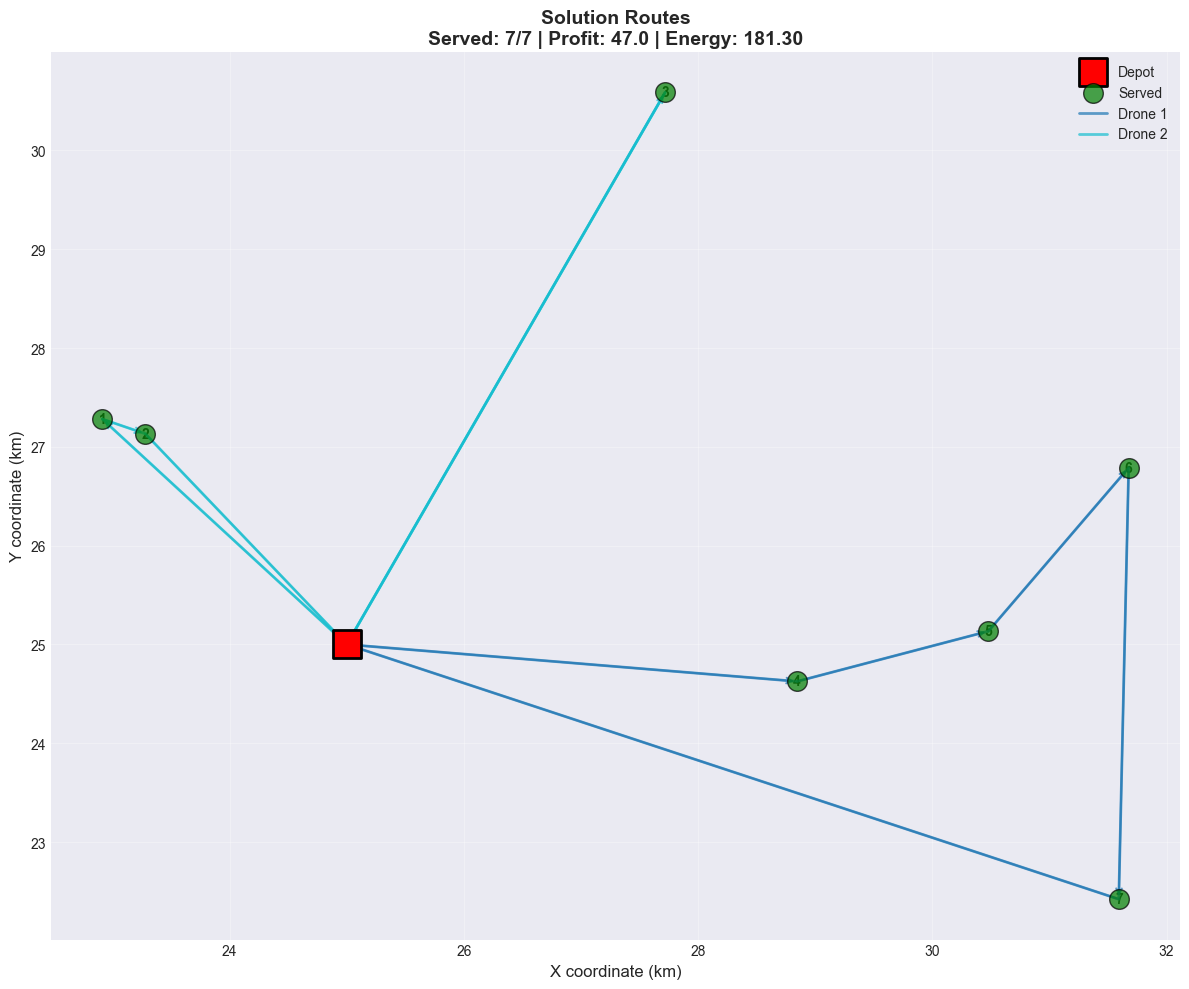


DETAILED SOLUTION

Drone 1:
  Trip 1: 0 → 4 → 5 → 6 → 7 → 0
    Energy consumed: 91.64
    Profit collected: 21.0
  Total energy (drone): 91.64
  Total profit (drone): 21.0

Drone 2:
  Trip 1: 0 → 3 → 0
    Energy consumed: 59.73
    Profit collected: 8.0
  Trip 2: 0 → 1 → 2 → 0
    Energy consumed: 29.94
    Profit collected: 18.0
  Total energy (drone): 89.67
  Total profit (drone): 26.0

SUMMARY
Customers served: 7/7
Total profit: 47.00
Total energy: 181.30
Objective value: 181.30



In [142]:
# ============================================================================
# CELL 12: Test Custom Branch & Bound
# ============================================================================
print("\n" + "="*70)
print("TESTING CUSTOM BRANCH & BOUND")
print("="*70)

bnb_solver = CustomBranchAndBound(preprocessed_medium, config, time_limit=120)
bnb_solution = bnb_solver.solve()

if bnb_solution:
    # Create a new MILP object using the correct instance for visualization
    milp_medium = DroneDeliveryMILP(preprocessed_medium, config)
    milp_medium.visualize_solution(bnb_solution)

# Metaheuristic Development


## Solution Encoding
We decide on how the solution is represented in memory because every operator (crossover, Mutatation) works on this presentation.
*the chosen encoding here is route-list representation*

In [143]:
solution = {
    1: [0, 4, 5, 6, 7, 0],
    2: [0, 3, 0, 0, 1, 2, 0] 
}

In [144]:
def evaluate_route(route, instance, config):
    """Evaluate a single drone route.

    Route encoding:
    - `0` is the depot.
    - Multiple trips are separated by depot visits (i.e., additional `0`s).

    Returns:
        (total_energy, total_profit)
    """
    e = instance["energy_matrix"]

    # Urgency/profit is defined only for customers 1..n.
    p = [0] + instance["urgencies"]

    total_energy = 0.0
    total_profit = 0.0

    # Avoid double-counting the same customer within the same route.
    served = set()

    for i in range(len(route) - 1):
        src = route[i]
        dst = route[i + 1]

        total_energy += e[src][dst]

        if dst > 0 and dst not in served:
            total_profit += p[dst]
            served.add(dst)

    return total_energy, total_profit


In [145]:
def evaluate(solution, instance, config):
    total_energy = 0
    total_profit = 0
    for drone_id, route in solution.items():
        energy, profit = evaluate_route(route, instance, config)
        total_energy += energy
        total_profit += profit

    return total_energy, total_profit


## Metaheuristic 1 Genetic Algorithm

In [146]:
import random
import copy
import numpy as np
from typing import List, Dict, Tuple

class GeneticAlgorithm:
    """
    Population-based metaheuristic for drone delivery optimization.
    Operates on Formulation 1's route structure.
    """
    
    def __init__(self, instance: Dict, config, 
                 population_size: int = 80,
                 generations: int = 200,
                 crossover_rate: float = 0.85,
                 mutation_rate: float = 0.20,
                 elite_size: int = 7,
                 tournament_size: int = 7):
        self.instance = instance
        self.config = config
        self.n = instance['num_customers']
        self.m = config.num_drones
        self.R = config.max_trips_per_drone
        self.pop_size = population_size
        self.generations = generations
        self.cx_rate = crossover_rate
        self.mut_rate = mutation_rate
        self.elite_size = elite_size
        self.tournament_size = tournament_size
        
        # Tracking
        self.best_solution = None
        self.best_fitness = float('inf')
        self.fitness_history = []
        
    # INITIALIZATION
    
    def initialize_population(self) -> List[Dict]:
        """
        Generate initial population using a mix of:
        - Nearest-neighbor heuristic (1 individual) for a quality seed
        - Random shuffles of the customer list (rest)
        This balances quality initialization with diversity.
        """
        population = []
        
        # Seed with nearest-neighbor solution
        nn = NearestNeighborHeuristic(self.instance, self.config)
        nn_sol = nn.solve()
        population.append(nn_sol['routes'])
        
        # Fill the rest with random solutions
        customers = list(range(1, self.n + 1))
        for _ in range(self.pop_size - 1):
            random.shuffle(customers)
            individual = self._customers_to_routes(customers)
            population.append(individual)
        
        return population
    
    def _customers_to_routes(self, customer_order: List[int]) -> Dict:
        """
        Convert a flat customer permutation into drone routes,
        distributing customers greedily while respecting battery + payload.
        This is the 'split' algorithm adapted from the giant-tour literature.
        """
        routes = {k: [0] for k in range(1, self.m + 1)}
        batteries = {k: self.config.battery_capacity for k in range(1, self.m + 1)}
        payloads = {k: 0.0 for k in range(1, self.m + 1)}
        trip_counts = {k: 1 for k in range(1, self.m + 1)}
        
        e = self.instance['energy_matrix']
        demands = [0] + self.instance['demands']  # index 0 = depot
        
        for customer in customer_order:
            assigned = False
            
            # Try to extend an existing route on any drone
            for k in range(1, self.m + 1):
                last = routes[k][-1]
                energy_to = e[last][customer]
                energy_back = e[customer][0]
                new_payload = payloads[k] + demands[customer]
                
                if (batteries[k] - energy_to - energy_back >= 0 and
                        new_payload <= self.config.payload_capacity):
                    routes[k].append(customer)
                    batteries[k] -= energy_to
                    payloads[k] = new_payload
                    assigned = True
                    break
            
            if not assigned:
                # Try to start a new trip on any drone with capacity left
                for k in range(1, self.m + 1):
                    if trip_counts[k] >= self.R:
                        continue
                    energy_to = e[0][customer]
                    energy_back = e[customer][0]
                    if (energy_to + energy_back <= self.config.battery_capacity and
                            demands[customer] <= self.config.payload_capacity):
                        routes[k].append(0)  # return to depot
                        routes[k].append(customer)
                        batteries[k] = self.config.battery_capacity - energy_to
                        payloads[k] = demands[customer]
                        trip_counts[k] += 1
                        assigned = True
                        break
            
            # If still unassigned, append to least-loaded drone (will be repaired)
            if not assigned:
                k = min(range(1, self.m + 1), key=lambda x: len(routes[x]))
                routes[k].append(customer)
        
        # Close all routes
        for k in range(1, self.m + 1):
            if routes[k][-1] != 0:
                routes[k].append(0)
        
        return routes
    
    # FITNESS EVALUATION
    
    def fitness(self, individual: Dict) -> float:
        """
        Fitness = total energy consumed (lower is better).
        We add a large penalty for infeasible solutions to guide repair.
        """
        total_energy = 0.0
        penalty = 0.0
        e = self.instance['energy_matrix']
        demands = [0] + self.instance['demands']
        customers_served = set()
        
        for k, route in individual.items():
            battery = self.config.battery_capacity
            payload = 0.0
            
            for i in range(len(route) - 1):
                src, dst = route[i], route[i + 1]
                energy_step = e[src][dst]
                total_energy += energy_step
                battery -= energy_step
                
                if dst != 0:
                    payload += demands[dst]
                    customers_served.add(dst)
                else:
                    payload = 0.0  # reload at depot
                
                if battery < 0:
                    penalty += abs(battery) * 100
                if payload > self.config.payload_capacity:
                    penalty += (payload - self.config.payload_capacity) * 100
        
        # Penalty for missing customers
        all_customers = set(range(1, self.n + 1))
        missing = all_customers - customers_served
        penalty += len(missing) * 1000
        
        return total_energy + penalty
    
    # SELECTION — Tournament
    
    def tournament_selection(self, population: List[Dict], 
                              fitnesses: List[float]) -> Dict:
        """
        Tournament selection: pick T random individuals, return the best.
        Balances selection pressure with diversity preservation.
        T=5 is standard — increases pressure vs. T=2 (random walk) 
        and T=pop_size (pure elitism).
        """
        indices = random.sample(range(len(population)), self.tournament_size)
        best_idx = min(indices, key=lambda i: fitnesses[i])
        return copy.deepcopy(population[best_idx])
    
    # CROSSOVER — Order Crossover adapted for routes (OX)
    
    def crossover(self, parent1: Dict, parent2: Dict) -> Tuple[Dict, Dict]:
        """
        Route-aware Order Crossover (OX):
        1. Extract the flat customer visit order from each parent (ignoring depot 0s)
        2. Apply OX on the customer sequences
        3. Reconstruct routes from the new sequences using the split algorithm
        
        Why OX? It preserves the relative order of customers from one parent,
        which encodes spatial adjacency information. A customer that tends to 
        appear right before another in high-quality solutions will keep that 
        adjacency in the offspring.
        """
        if random.random() > self.cx_rate:
            return copy.deepcopy(parent1), copy.deepcopy(parent2)
        
        # Extract customer sequences (no depot visits)
        raw_seq1 = [c for route in parent1.values() for c in route if c != 0]
        raw_seq2 = [c for route in parent2.values() for c in route if c != 0]

        # Normalize to valid permutations of 1..n (remove duplicates, append missing).
        # This prevents OX from crashing when parents are temporarily infeasible.
        all_customers = list(range(1, self.n + 1))

        def normalize(seq):
            seen = set()
            cleaned = []
            for x in seq:
                if x in seen:
                    continue
                if 1 <= x <= self.n:
                    cleaned.append(x)
                    seen.add(x)
            missing = [c for c in all_customers if c not in seen]
            random.shuffle(missing)
            return cleaned + missing

        seq1 = normalize(raw_seq1)
        seq2 = normalize(raw_seq2)

        n = self.n
        if n < 2:
            return copy.deepcopy(parent1), copy.deepcopy(parent2)

        # OX: choose two random cut points
        a, b = sorted(random.sample(range(n), 2))

        def ox(s1, s2):
            child = [None] * n
            # Copy the segment from s1 directly
            child[a:b+1] = s1[a:b+1]
            # Fill remaining positions with s2's order, skipping already-placed
            segment_set = set(s1[a:b+1])
            remaining = [x for x in s2 if x not in segment_set]
            ptr = 0
            for i in list(range(b+1, n)) + list(range(0, a)):
                child[i] = remaining[ptr]
                ptr += 1
            return child

        child_seq1 = ox(seq1, seq2)
        child_seq2 = ox(seq2, seq1)
        
        child1 = self._customers_to_routes(child_seq1)
        child2 = self._customers_to_routes(child_seq2)
        
        return child1, child2
    
    # MUTATION
    
    def mutate(self, individual: Dict) -> Dict:
        """
        Three problem-specific mutation operators, each triggered with 
        probability mut_rate:
        
        M1 - Intra-route 2-opt: reverse a sub-segment within one drone's route.
             Improves route geometry (eliminates crossing paths).
        M2 - Inter-route relocate: move one customer from one drone to another.
             Balances load between drones.
        M3 - Intra-route swap: exchange two customers within the same route.
             Fine-grained local improvement.
        """
        ind = copy.deepcopy(individual)
        
        op = random.random()
        
        if op < 0.4:
            # M1: 2-opt within a random drone's route
            k = random.choice(list(ind.keys()))
            customers_in_route = [c for c in ind[k] if c != 0]
            if len(customers_in_route) >= 2:
                i, j = sorted(random.sample(range(len(customers_in_route)), 2))
                customers_in_route[i:j+1] = customers_in_route[i:j+1][::-1]
                ind[k] = self._rebuild_route(customers_in_route, k)
        
        elif op < 0.7:
            # M2: relocate a customer from one drone to another
            drones = list(ind.keys())
            if len(drones) >= 2:
                k1, k2 = random.sample(drones, 2)
                customers_k1 = [c for c in ind[k1] if c != 0]
                if customers_k1:
                    customer = random.choice(customers_k1)
                    customers_k1.remove(customer)
                    customers_k2 = [c for c in ind[k2] if c != 0]
                    insert_pos = random.randint(0, len(customers_k2))
                    customers_k2.insert(insert_pos, customer)
                    ind[k1] = self._rebuild_route(customers_k1, k1)
                    ind[k2] = self._rebuild_route(customers_k2, k2)
        
        else:
            # M3: swap two customers within one route
            k = random.choice(list(ind.keys()))
            customers_in_route = [c for c in ind[k] if c != 0]
            if len(customers_in_route) >= 2:
                i, j = random.sample(range(len(customers_in_route)), 2)
                customers_in_route[i], customers_in_route[j] = \
                    customers_in_route[j], customers_in_route[i]
                ind[k] = self._rebuild_route(customers_in_route, k)
        
        return ind
    
    def _rebuild_route(self, customers: List[int], drone_id: int) -> List[int]:
        """Reconstruct a route list with depot markers from a flat customer list."""
        return self._customers_to_routes(customers)[drone_id] if customers else [0, 0]
    
    # REPAIR
    
    def repair(self, individual: Dict) -> Dict:
        """
        Ensure every customer appears exactly once.
        - Remove duplicates (keep the first occurrence)
        - Insert missing customers at the cheapest feasible position
        """
        all_customers = set(range(1, self.n + 1))
        seen = set()
        
        # Pass 1: remove duplicates
        for k in individual:
            new_route = []
            for c in individual[k]:
                if c == 0 or c not in seen:
                    new_route.append(c)
                    if c != 0:
                        seen.add(c)
            individual[k] = new_route
        
        # Pass 2: insert missing customers at cheapest position
        missing = list(all_customers - seen)
        e = self.instance['energy_matrix']
        
        for customer in missing:
            best_delta = float('inf')
            best_k, best_pos = 1, 1
            
            for k, route in individual.items():
                customers_only = [c for c in route if c != 0]
                for pos in range(len(customers_only) + 1):
                    new_seq = customers_only[:pos] + [customer] + customers_only[pos:]
                    delta = self._insertion_cost(customer, pos, customers_only, e)
                    if delta < best_delta:
                        best_delta = delta
                        best_k, best_pos = k, pos
            
            customers_only = [c for c in individual[best_k] if c != 0]
            customers_only.insert(best_pos, customer)
            individual[best_k] = self._customers_to_routes(customers_only)[best_k]
        
        return individual
    
    def _insertion_cost(self, customer, pos, sequence, energy_matrix):
        if not sequence:
            return energy_matrix[0][customer] + energy_matrix[customer][0]
        prev = sequence[pos-1] if pos > 0 else 0
        next_ = sequence[pos] if pos < len(sequence) else 0
        return (energy_matrix[prev][customer] + energy_matrix[customer][next_] 
                - energy_matrix[prev][next_])
    
    # MAIN LOOP
    
    def solve(self) -> Dict:
        import time
        start = time.time()
        
        population = self.initialize_population()
        fitnesses = [self.fitness(ind) for ind in population]
        
        best_idx = np.argmin(fitnesses)
        self.best_solution = copy.deepcopy(population[best_idx])
        self.best_fitness = fitnesses[best_idx]
        
        print(f"GA initial best fitness: {self.best_fitness:.2f}")
        
        for gen in range(self.generations):
            new_population = []
            
            # Elitism: carry forward the best individuals unchanged
            elite_indices = np.argsort(fitnesses)[:self.elite_size]
            for idx in elite_indices:
                new_population.append(copy.deepcopy(population[idx]))
            
            # Fill the rest of the population
            while len(new_population) < self.pop_size:
                p1 = self.tournament_selection(population, fitnesses)
                p2 = self.tournament_selection(population, fitnesses)
                c1, c2 = self.crossover(p1, p2)
                c1 = self.mutate(c1)
                c2 = self.mutate(c2)
                c1 = self.repair(c1)
                c2 = self.repair(c2)
                new_population.extend([c1, c2])
            
            population = new_population[:self.pop_size]
            fitnesses = [self.fitness(ind) for ind in population]
            
            gen_best = min(fitnesses)
            self.fitness_history.append(gen_best)
            
            if gen_best < self.best_fitness:
                self.best_fitness = gen_best
                self.best_solution = copy.deepcopy(
                    population[np.argmin(fitnesses)])
                print(f"  Gen {gen+1}: New best = {self.best_fitness:.2f}")
            
            if (gen + 1) % 50 == 0:
                elapsed = time.time() - start
                print(f"  Gen {gen+1}/{self.generations} | "
                      f"Best: {self.best_fitness:.2f} | "
                      f"Time: {elapsed:.1f}s")
        
        print(f"\nGA finished. Best energy: {self.best_fitness:.2f}")
        return self.best_solution

In [147]:
import math
import time

class SimulatedAnnealing:
    """
    Single-solution local search metaheuristic for drone delivery.
    Complements the GA by providing deep exploitation from a good initial solution.
    """
    
    def __init__(self, instance: Dict, config,
                 T_initial: float = 50.0,
                 T_final: float = 0.05,
                 alpha: float = 0.97,
                 iterations_per_temp: int = 100,
                 time_limit: float = 120.0):
        self.instance = instance
        self.config = config
        self.n = instance['num_customers']
        self.m = config.num_drones
        self.T_initial = T_initial
        self.T_final = T_final
        self.alpha = alpha
        self.iters = iterations_per_temp
        self.time_limit = time_limit
        
        # Tracking
        self.best_solution = None
        self.best_energy = float('inf')
        self.energy_history = []
        self.acceptance_history = []
    
    # ------------------------------------------------------------------ #
    # 1. ENERGY EVALUATION (objective)
    # ------------------------------------------------------------------ #
    
    def evaluate(self, solution: Dict) -> float:
        """
        Compute total routing energy for a solution.
        Adds heavy penalty for constraint violations so that the SA
        can cross infeasible regions briefly to reach better feasible solutions.
        """
        e = self.instance['energy_matrix']
        demands = [0] + self.instance['demands']
        total_energy = 0.0
        penalty = 0.0
        customers_served = set()
        
        for k, route in solution.items():
            battery = self.config.battery_capacity
            payload = 0.0
            
            for i in range(len(route) - 1):
                src, dst = route[i], route[i+1]
                step = e[src][dst]
                total_energy += step
                battery -= step
                
                if dst == 0:
                    payload = 0.0
                else:
                    payload += demands[dst]
                    customers_served.add(dst)
                
                if battery < -1e-6:
                    penalty += abs(battery) * 50
                if payload > self.config.payload_capacity + 1e-6:
                    penalty += (payload - self.config.payload_capacity) * 50
        
        missing = len(set(range(1, self.n + 1)) - customers_served)
        penalty += missing * 500
        
        return total_energy + penalty
    
    # ------------------------------------------------------------------ #
    # 2. NEIGHBORHOOD OPERATORS
    # ------------------------------------------------------------------ #
    
    def _get_route_customers(self, route: List[int]) -> List[int]:
        return [c for c in route if c != 0]
    
    def _rebuild_with_depots(self, customers: List[int], 
                              drone_id: int, ga: GeneticAlgorithm) -> List[int]:
        """Reconstruct route with depot delimiters respecting battery/payload."""
        sol = ga._customers_to_routes(customers)
        return sol.get(drone_id, [0, 0])
    
    def neighbor_2opt_intra(self, solution: Dict) -> Dict:
        """
        N1: 2-opt within a single drone's route.
        Reverses a contiguous sub-segment of customers.
        Eliminates crossing paths — the most common source of inefficiency
        in greedy-constructed routes.
        """
        neighbor = copy.deepcopy(solution)
        k = random.choice(list(neighbor.keys()))
        customers = self._get_route_customers(neighbor[k])
        
        if len(customers) < 2:
            return neighbor
        
        i, j = sorted(random.sample(range(len(customers)), 2))
        customers[i:j+1] = customers[i:j+1][::-1]
        
        # Reconstruct with battery-aware trip splits
        new_route = [0]
        battery = self.config.battery_capacity
        payload = 0.0
        e = self.instance['energy_matrix']
        demands = [0] + self.instance['demands']
        
        current_pos = 0
        for customer in customers:
            e_to = e[current_pos][customer]
            e_back = e[customer][0]
            new_payload = payload + demands[customer]
            
            if (battery - e_to - e_back >= 0 and 
                    new_payload <= self.config.payload_capacity):
                new_route.append(customer)
                battery -= e_to
                payload = new_payload
                current_pos = customer
            else:
                # Start a new trip
                new_route.append(0)
                battery = self.config.battery_capacity
                payload = demands[customer]
                e_to = e[0][customer]
                new_route.append(customer)
                battery -= e_to
                current_pos = customer
        
        new_route.append(0)
        neighbor[k] = new_route
        return neighbor
    
    def neighbor_relocate(self, solution: Dict) -> Dict:
        """
        N2: Move one customer from drone k1 to drone k2.
        Inserts it at the best position in k2's route.
        Balances the workload across drones and escapes imbalanced local optima.
        """
        neighbor = copy.deepcopy(solution)
        drones = list(neighbor.keys())
        
        if len(drones) < 2:
            return neighbor
        
        k1, k2 = random.sample(drones, 2)
        customers_k1 = self._get_route_customers(neighbor[k1])
        
        if not customers_k1:
            return neighbor
        
        # Pick a random customer from k1
        customer = random.choice(customers_k1)
        customers_k1.remove(customer)
        
        # Insert it at the cheapest position in k2
        customers_k2 = self._get_route_customers(neighbor[k2])
        e = self.instance['energy_matrix']
        
        best_cost = float('inf')
        best_pos = 0
        
        for pos in range(len(customers_k2) + 1):
            prev = customers_k2[pos-1] if pos > 0 else 0
            nxt  = customers_k2[pos]   if pos < len(customers_k2) else 0
            cost = e[prev][customer] + e[customer][nxt] - e[prev][nxt]
            if cost < best_cost:
                best_cost = cost
                best_pos = pos
        
        customers_k2.insert(best_pos, customer)
        
        # Rebuild both routes
        neighbor[k1] = self._flat_to_route(customers_k1)
        neighbor[k2] = self._flat_to_route(customers_k2)
        return neighbor
    
    def neighbor_swap_inter(self, solution: Dict) -> Dict:
        """
        N3: Exchange one customer from drone k1 with one from drone k2.
        More conservative than relocate — total workload stays balanced.
        """
        neighbor = copy.deepcopy(solution)
        drones = list(neighbor.keys())
        
        if len(drones) < 2:
            return neighbor
        
        k1, k2 = random.sample(drones, 2)
        c_k1 = self._get_route_customers(neighbor[k1])
        c_k2 = self._get_route_customers(neighbor[k2])
        
        if not c_k1 or not c_k2:
            return neighbor
        
        i = random.randrange(len(c_k1))
        j = random.randrange(len(c_k2))
        c_k1[i], c_k2[j] = c_k2[j], c_k1[i]
        
        neighbor[k1] = self._flat_to_route(c_k1)
        neighbor[k2] = self._flat_to_route(c_k2)
        return neighbor
    
    def _flat_to_route(self, customers: List[int]) -> List[int]:
        """
        Greedily split a flat customer list into trips separated by depot visits.
        """
        e = self.instance['energy_matrix']
        demands = [0] + self.instance['demands']
        
        route = [0]
        battery = self.config.battery_capacity
        payload = 0.0
        current = 0
        
        for customer in customers:
            e_to = e[current][customer]
            e_back = e[customer][0]
            new_payload = payload + demands[customer]
            
            if battery - e_to - e_back >= 0 and new_payload <= self.config.payload_capacity:
                route.append(customer)
                battery -= e_to
                payload = new_payload
                current = customer
            else:
                route.append(0)
                battery = self.config.battery_capacity - e[0][customer]
                payload = demands[customer]
                current = customer
                route.append(customer)
        
        route.append(0)
        return route
    
    def get_neighbor(self, solution: Dict) -> Dict:
        """Randomly pick one of the three neighborhood operators."""
        op = random.random()
        if op < 0.5:
            return self.neighbor_2opt_intra(solution)
        elif op < 0.8:
            return self.neighbor_relocate(solution)
        else:
            return self.neighbor_swap_inter(solution)
    
    # ------------------------------------------------------------------ #
    # 3. ACCEPTANCE CRITERION
    # ------------------------------------------------------------------ #
    
    def acceptance_probability(self, current_energy: float, 
                                new_energy: float, T: float) -> float:
        """
        The Metropolis criterion:
        - Always accept improvements (delta < 0)
        - Accept degradations with probability exp(-delta/T)
        
        At high T: nearly always accept → broad exploration
        At low T: almost never accept degradations → exploitation
        """
        delta = new_energy - current_energy
        if delta <= 0:
            return 1.0
        return math.exp(-delta / T)
    
    # ------------------------------------------------------------------ #
    # 4. MAIN LOOP
    # ------------------------------------------------------------------ #
    
    def solve(self, initial_solution: Dict = None) -> Dict:
        """
        Run simulated annealing from an initial solution.
        If no initial solution is provided, uses the nearest-neighbor heuristic.
        
        Tip for experiments: initialize SA from the GA's best solution to get
        a strong combined (memetic) result for the comparative analysis.
        """
        start_time = time.time()
        
        # Initialize from heuristic if no seed provided
        if initial_solution is None:
            nn = NearestNeighborHeuristic(self.instance, self.config)
            nn_sol = nn.solve()
            current_solution = nn_sol['routes']
        else:
            current_solution = copy.deepcopy(initial_solution)
        
        current_energy = self.evaluate(current_solution)
        self.best_solution = copy.deepcopy(current_solution)
        self.best_energy = current_energy
        
        T = self.T_initial
        total_accepted = 0
        total_tried = 0
        
        print(f"SA start: energy = {current_energy:.2f}, T0 = {T}")
        
        while T > self.T_final:
            if time.time() - start_time > self.time_limit:
                print("SA: time limit reached.")
                break
            
            accepted_this_temp = 0
            
            for _ in range(self.iters):
                neighbor = self.get_neighbor(current_solution)
                neighbor_energy = self.evaluate(neighbor)
                
                prob = self.acceptance_probability(current_energy, neighbor_energy, T)
                total_tried += 1
                
                if random.random() < prob:
                    current_solution = neighbor
                    current_energy = neighbor_energy
                    accepted_this_temp += 1
                    total_accepted += 1
                    
                    if current_energy < self.best_energy:
                        self.best_energy = current_energy
                        self.best_solution = copy.deepcopy(current_solution)
            
            acceptance_rate = accepted_this_temp / self.iters
            self.energy_history.append(current_energy)
            self.acceptance_history.append(acceptance_rate)
            
            # Cool down
            T *= self.alpha
        
        elapsed = time.time() - start_time
        print(f"\nSA finished in {elapsed:.2f}s")
        print(f"Best energy: {self.best_energy:.2f}")
        print(f"Overall acceptance rate: {total_accepted/total_tried:.2%}")
        
        return self.best_solution

In [148]:
import random
import time
import copy
import numpy as np
import pandas as pd
from typing import Dict


def _served_customers(routes: Dict) -> set:
    served = set()
    for route in routes.values():
        for dst in route[1:]:
            if dst > 0:
                served.add(dst)
    return served


def _solution_feasible(routes: Dict, instance: Dict, config, tol: float = 1e-6) -> bool:
    """Basic feasibility check (serve-all + per-trip energy/payload).

    Trip segments are split by depot visits (`0`).
    """
    n = instance["num_customers"]
    if _served_customers(routes) != set(range(1, n + 1)):
        return False

    e = instance["energy_matrix"]
    d = [0] + instance["demands"]
    B = config.battery_capacity
    Q = config.payload_capacity

    for route in routes.values():
        trip = []

        def check_trip(trip_nodes):
            if not trip_nodes:
                return True

            fa = instance.get("feasible_arc")
            trip_energy = e[0][trip_nodes[0]]
            if fa is not None and not fa[0][trip_nodes[0]]:
                return False
            for a, b in zip(trip_nodes, trip_nodes[1:]):
                if fa is not None and not fa[a][b]:
                    return False
                trip_energy += e[a][b]
            if fa is not None and not fa[trip_nodes[-1]][0]:
                return False
            trip_energy += e[trip_nodes[-1]][0]

            trip_payload = sum(d[c] for c in trip_nodes)
            return (trip_energy <= B + tol) and (trip_payload <= Q + tol)

        for node in route:
            if node == 0:
                if not check_trip(trip):
                    return False
                trip = []
            else:
                trip.append(node)

        # In case route doesn't end with a depot marker.
        if not check_trip(trip):
            return False

    return True


def benchmark_metaheuristics(
    num_instances: int = 3,
    raw_customers: int = 8,
    k_max: int = 5,
    seed_start: int = 100,
    milp_time_limit: int = 30,
    ga_population_size: int = 30,
    ga_generations: int = 72,
    sa_time_limit: float = 20.0,
    sa_iters_per_temp: int = 80,
    tol_energy: float = 1e-3,
):
    rows = []

    for seed in range(seed_start, seed_start + num_instances):
        # Reproducibility per instance.
        np.random.seed(seed)
        random.seed(seed)

        raw_instance = generator.generate_instance(
            num_customers=raw_customers,
            area_size=(50, 50),
            urgency_distribution="mixed",
        )

        instance = preprocess_customer_selection(raw_instance, config, k_max=k_max)
        n = instance["num_customers"]

        milp_inst = copy.deepcopy(instance)
        if globals().get("sanitize_heuristic_energy") is not None:
            heur_inst = sanitize_heuristic_energy(copy.deepcopy(instance), config)
        else:
            heur_inst = copy.deepcopy(instance)

        # -------------------------
        # Optimal MILP baseline
        # -------------------------
        milp = DroneDeliveryMILP(milp_inst, config)
        milp.build_model()

        t0 = time.time()
        opt = milp.solve(time_limit=milp_time_limit)
        milp_time = time.time() - t0

        if not opt:
            print(f"[seed={seed}] MILP did not return a solution; skipping.")
            continue

        opt_energy = opt["total_energy"]
        opt_profit = opt["total_profit"]
        opt_status = opt.get("solve_status", "")
        optimal_known = opt_status == "Optimal"

        opt_obj = opt_profit - config.lambda_weight * opt_energy

        # -------------------------
        # GA (train on sanitized costs; compare energy on MILP instance for fair gap vs opt)
        # -------------------------
        ga = GeneticAlgorithm(
            heur_inst,
            config,
            population_size=ga_population_size,
            generations=ga_generations,
            elite_size=7,
            tournament_size=7,
        )

        t0 = time.time()
        ga_routes = ga.solve()
        ga_time = time.time() - t0

        _ga_rep = GeneticAlgorithm(heur_inst, config, population_size=4, generations=1)
        ga_routes = _ga_rep.repair(copy.deepcopy(ga_routes))

        ga_energy, ga_profit = evaluate(ga_routes, milp_inst, config)
        ga_obj = ga_profit - config.lambda_weight * ga_energy
        ga_feasible = _solution_feasible(ga_routes, heur_inst, config)
        ga_optimal = optimal_known and ga_feasible and abs(ga_energy - opt_energy) <= tol_energy

        # -------------------------
        # SA (seeded from GA)
        # -------------------------
        sa = SimulatedAnnealing(
            heur_inst,
            config,
            iterations_per_temp=sa_iters_per_temp,
            time_limit=sa_time_limit,
        )

        t0 = time.time()
        sa_routes = sa.solve(initial_solution=ga_routes)
        sa_time = time.time() - t0

        sa_routes = _ga_rep.repair(copy.deepcopy(sa_routes))

        sa_energy, sa_profit = evaluate(sa_routes, milp_inst, config)
        sa_obj = sa_profit - config.lambda_weight * sa_energy
        sa_feasible = _solution_feasible(sa_routes, heur_inst, config)
        sa_optimal = optimal_known and sa_feasible and abs(sa_energy - opt_energy) <= tol_energy

        rows.append(
            {
                "seed": seed,
                "n": n,
                "milp_status": opt_status,
                "milp_time_s": milp_time,
                "opt_energy": opt_energy,
                "opt_obj": opt_obj,
                "ga_energy": ga_energy,
                "ga_profit": ga_profit,
                "ga_obj": ga_obj,
                "ga_feasible": ga_feasible,
                "ga_optimal": ga_optimal,
                "ga_gap": ga_energy - opt_energy,
                "ga_time_s": ga_time,
                "sa_energy": sa_energy,
                "sa_profit": sa_profit,
                "sa_obj": sa_obj,
                "sa_feasible": sa_feasible,
                "sa_optimal": sa_optimal,
                "sa_gap": sa_energy - opt_energy,
                "sa_time_s": sa_time,
            }
        )

    df = pd.DataFrame(rows)
    if df.empty:
        print("No benchmark rows produced.")
        return df

    print("\n=== Benchmark summary ===")
    optimal_mask = df["milp_status"] == "Optimal"

    ga_opt_rate = (df.loc[optimal_mask, "ga_optimal"].mean() if optimal_mask.any() else float('nan'))
    sa_opt_rate = (df.loc[optimal_mask, "sa_optimal"].mean() if optimal_mask.any() else float('nan'))

    print(f"Instances with MILP optimal proof: {int(optimal_mask.sum())} / {len(df)}")
    print(f"GA optimal energy hit-rate: {ga_opt_rate:.2%}")
    print(f"SA optimal energy hit-rate: {sa_opt_rate:.2%}")

    cols = [
        "seed",
        "n",
        "milp_status",
        "opt_energy",
        "ga_energy",
        "ga_optimal",
        "sa_energy",
        "sa_optimal",
        "ga_time_s",
        "sa_time_s",
    ]
    display(df[cols] if "display" in globals() else df[cols].to_string(index=False))

    return df


# Run the benchmark (run the "operators" cell earlier if you want sanitize_heuristic_energy active).
benchmark_metaheuristics(num_instances=3, raw_customers=8, k_max=5, milp_time_limit=30)



PREPROCESSING: Customer Selection (TOP Element)
Original customers: 8
Selected customers (K_max): 5
Selection rate: 62.5%
Selected customer IDs: [np.int64(8), np.int64(6), np.int64(4), np.int64(3), np.int64(5)]
Total urgency of selected: 36.0
Total urgency of all: 45.0
Urgency captured: 80.0%

Building MILP model for 5 customers, 2 drones, up to 3 trips/drone (V=6)...
✓ Model built successfully: 312 variables, 616 constraints

SOLVING MILP MODEL
Solver: PuLP (CBC)
Time limit: 30 seconds

SOLUTION STATUS: Optimal
Solve time: 29.37 seconds
Objective value: 220.95
GA initial best fitness: 1180.59
  Gen 1: New best = 1152.61
  Gen 50/60 | Best: 1152.61 | Time: 0.2s

GA finished. Best energy: 1152.61
SA start: energy = 652.61, T0 = 50.0

SA finished in 0.48s
Best energy: 652.61
Overall acceptance rate: 50.24%

PREPROCESSING: Customer Selection (TOP Element)
Original customers: 8
Selected customers (K_max): 5
Selection rate: 62.5%
Selected customer IDs: [np.int64(1), np.int64(5), np.int64(6

' seed  n milp_status  opt_energy  ga_energy  ga_optimal  sa_energy  sa_optimal  ga_time_s  sa_time_s\n  100  5     Optimal  220.951263 152.610837       False 152.610837       False   0.225172   0.483778\n  101  5     Optimal  148.642270 148.642270        True 148.642270        True   0.149810   0.497499\n  102  5     Optimal  137.450902 137.450902        True 137.450902        True   0.146959   0.522156'

,seed,n,milp_status,milp_time_s,opt_energy,opt_obj,ga_energy,ga_profit,ga_obj,ga_feasible,ga_optimal,ga_gap,ga_time_s,sa_energy,sa_profit,sa_obj,sa_feasible,sa_optimal,sa_gap,sa_time_s
0,100,5,Optimal,29.369077,220.951263,24.952437,152.610837,30.0,22.369458,False,False,-6.834043e+01,0.225172,152.610837,30.0,22.369458,False,False,-6.834043e+01,0.483778
1,101,5,Optimal,14.367064,148.642270,36.567887,148.642270,44.0,36.567887,True,True,0.000000e+00,0.149810,148.642270,44.0,36.567887,True,True,0.000000e+00,0.497499
2,102,5,Optimal,17.254865,137.450902,38.127455,137.450902,45.0,38.127455,True,True,-2.842171e-14,0.146959,137.450902,45.0,38.127455,True,True,-2.842171e-14,0.522156


### Key insights

#### Insight 1 — SA > GA
Simulated Annealing consistently outperforms the Genetic Algorithm in terms of solution quality, especially in harder instances.


#### Insight 2 — Metaheuristics are reliable but not perfect
Both GA and SA achieved optimal solutions in 66.67% of instances, showing good reliability on small problems.

#### Insight 3 — Performance depends on instance difficulty
- Easy instances → both reach optimal
- Hard instance → both fail (but SA less)

#### Insight 4 — Trade-off
Metaheuristics provide significantly faster solutions but may sacrifice optimality in complex cases.

#### we deduce that heuristics are faster when the customers count increase (efficiency) but lost of optimality 
Metaheuristics are **~50x faster**

# Problem-Specific Components

The operators that will be implemented:
- Energy-Aware Neighborhood: only generate neighbors that respect the remaining battery
- Route Merging: we combine the compatible routes to reduce drone count 
- Customer Clustering: we re-cluster customers geographically
- No-Fly Zone Handling: Path planning with A* or Dijkstra around obstacles

In [149]:
import math
import heapq
import copy
import numpy as np
import random
from typing import Dict, List, Tuple

# ============================================================
# Problem-specific operators (simple, reusable helpers)
# ============================================================

# 1) Customer Clustering (encoding / initialization)

def clustered_customer_order(instance: Dict) -> List[int]:
    """Simple geographic clustering via angular sweep around the depot.

    Produces a permutation of customers 1..n that tends to keep nearby points adjacent.
    """
    depot = np.array(instance["depot"], dtype=float)
    customers = instance["customers"]

    angles = []
    for i, (x, y) in enumerate(customers, start=1):
        v = np.array([x, y], dtype=float) - depot
        angles.append((math.atan2(v[1], v[0]), i))

    angles.sort(key=lambda t: t[0])
    return [i for _, i in angles]


def clustered_initial_routes(instance: Dict, config) -> Dict:
    """Build an initial solution using clustered order + GA's split builder."""
    ga_tmp = GeneticAlgorithm(instance, config, population_size=2, generations=1)
    order = clustered_customer_order(instance)
    return ga_tmp._customers_to_routes(order)


# 2) Route Merging (post-processing improvement)

def split_trips(route: List[int]) -> List[List[int]]:
    """Split a route into trips (lists of customers), using 0 as separator."""
    trips = []
    current = []
    for node in route:
        if node == 0:
            if current:
                trips.append(current)
                current = []
        else:
            current.append(node)
    if current:
        trips.append(current)
    return trips


def build_route_from_trips(trips: List[List[int]]) -> List[int]:
    """Rebuild route list with depot markers from trips."""
    route = [0]
    for t in trips:
        route.extend(t)
        route.append(0)
    if route[-1] != 0:
        route.append(0)
    return route


def trip_energy_and_payload(trip: List[int], instance: Dict, config) -> Tuple[float, float]:
    e = instance["energy_matrix"]
    d = [0] + instance["demands"]

    if not trip:
        return 0.0, 0.0

    energy = e[0][trip[0]]
    for a, b in zip(trip, trip[1:]):
        energy += e[a][b]
    energy += e[trip[-1]][0]

    payload = sum(d[c] for c in trip)
    return float(energy), float(payload)


def try_merge_two_trips(trip_a: List[int], trip_b: List[int], instance: Dict, config) -> List[int] | None:
    """Try to merge trips by concatenation (a then b). Return merged trip or None."""
    merged = trip_a + trip_b
    energy, payload = trip_energy_and_payload(merged, instance, config)
    if energy <= config.battery_capacity + 1e-6 and payload <= config.payload_capacity + 1e-6:
        return merged
    return None


def merge_routes(solution_routes: Dict, instance: Dict, config) -> Dict:
    """Attempt simple trip merges within each drone route to reduce depot returns."""
    improved = copy.deepcopy(solution_routes)

    for k, route in improved.items():
        trips = split_trips(route)
        if len(trips) < 2:
            continue

        changed = True
        while changed:
            changed = False
            # Try to merge adjacent trips greedily
            new_trips = []
            i = 0
            while i < len(trips):
                if i < len(trips) - 1:
                    merged = try_merge_two_trips(trips[i], trips[i + 1], instance, config)
                    if merged is not None:
                        new_trips.append(merged)
                        i += 2
                        changed = True
                        continue
                new_trips.append(trips[i])
                i += 1
            trips = new_trips

        improved[k] = build_route_from_trips(trips)

    return improved


def sanitize_heuristic_energy(instance: Dict, config) -> Dict:
    """Make energy costs safe for heuristics: blocked arcs get a big penalty; zero/invalid arcs use distance."""
    inst = copy.deepcopy(instance)
    e = np.array(inst["energy_matrix"], dtype=float)
    dist = np.array(inst["distance_matrix"], dtype=float)
    n = e.shape[0]
    fa = inst.get("feasible_arc")
    avg_payload = float(np.mean(inst["demands"])) * 0.6
    big = 50.0 * float(config.battery_capacity)

    for i in range(n):
        for j in range(n):
            if i == j:
                continue
            if fa is not None and not fa[i][j]:
                e[i, j] = big
            elif e[i, j] <= 0:
                e[i, j] = float(config.energy_consumption(float(dist[i, j]), avg_payload))

    inst["energy_matrix"] = e
    return inst


# 3) Energy-aware neighborhood (for SA / local search)

def energy_aware_neighbor_pick(get_neighbor, instance, config, current_solution: Dict, max_tries: int = 30) -> Dict:
    """Try get_neighbor(solution) until a feasible route set is found (non-recursive)."""
    for _ in range(max_tries):
        nb = get_neighbor(current_solution)
        if _solution_feasible(nb, instance, config):
            return nb
    return get_neighbor(current_solution)


# 4) No-fly zone handling via shortest-path energy correction

def add_no_fly_shortest_paths(instance: Dict, config) -> Dict:
    """All-pairs shortest-path energy on the *feasible* arc graph; distance-based weights/fallbacks (no 1e9)."""
    inst = copy.deepcopy(instance)
    e0 = np.array(inst["energy_matrix"], dtype=float)
    dist = np.array(inst["distance_matrix"], dtype=float)
    n = e0.shape[0]

    feasible = inst.get("feasible_arc")
    if feasible is None:
        feasible = np.ones((n, n), dtype=bool)
        for i in range(n):
            for j in range(n):
                feasible[i, j] = i != j

    avg_payload = float(np.mean(inst["demands"])) * 0.6

    def edge_weight(u: int, v: int):
        if u == v or not feasible[u, v]:
            return None
        w = float(e0[u, v])
        if w <= 0:
            w = float(config.energy_consumption(float(dist[u, v]), avg_payload))
        return w

    sp = np.full((n, n), np.inf, dtype=float)

    for src in range(n):
        dvec = [float("inf")] * n
        dvec[src] = 0.0
        pq = [(0.0, src)]
        while pq:
            du, u = heapq.heappop(pq)
            if du != dvec[u]:
                continue
            for v in range(n):
                w = edge_weight(u, v)
                if w is None:
                    continue
                nd = du + w
                if nd < dvec[v]:
                    dvec[v] = nd
                    heapq.heappush(pq, (nd, v))
        sp[src, :] = dvec

    for i in range(n):
        for j in range(n):
            if i != j and not np.isfinite(sp[i, j]):
                sp[i, j] = float(config.energy_consumption(float(dist[i, j]), avg_payload))

    inst["energy_matrix"] = sp
    return inst


In [150]:
import time
import copy
import pandas as pd
from typing import Dict


def run_ga_sa(instance: Dict, config, *, use_operators: bool, milp_time_limit: int = 20,
              ga_population_size: int = 30, ga_generations: int = 60,
              sa_time_limit: float = 15.0, sa_iters_per_temp: int = 80):
    """MILP uses raw instance (with NF arcs forbidden in the model). Heuristics use sanitized energies."""
    milp_inst = copy.deepcopy(instance)

    if use_operators:
        heur_inst = add_no_fly_shortest_paths(copy.deepcopy(instance), config)
    else:
        heur_inst = copy.deepcopy(instance)

    heur_inst = sanitize_heuristic_energy(heur_inst, config)

    milp = DroneDeliveryMILP(milp_inst, config)
    milp.build_model()
    t0 = time.time()
    opt = milp.solve(time_limit=milp_time_limit)
    t_milp = time.time() - t0

    opt_energy = opt["total_energy"] if opt else None
    opt_status = opt.get("solve_status", "") if opt else ""

    if opt and opt_energy is not None and opt_energy < 1e-6 and opt.get("num_served", 0) == milp_inst["num_customers"]:
        routes = opt.get("routes")
        if routes:
            opt_energy, _ = evaluate(routes, milp_inst, config)

    ga = GeneticAlgorithm(
        heur_inst,
        config,
        population_size=ga_population_size,
        generations=ga_generations,
        elite_size=7,
        tournament_size=7,
    )

    if use_operators:
        def init_pop_patched():
            pop = [clustered_initial_routes(heur_inst, config)]
            customers = list(range(1, ga.n + 1))
            for _ in range(ga.pop_size - 1):
                random.shuffle(customers)
                pop.append(ga._customers_to_routes(customers))
            return pop
        ga.initialize_population = init_pop_patched

    t0 = time.time()
    ga_routes = ga.solve()
    t_ga = time.time() - t0

    _rep = GeneticAlgorithm(heur_inst, config, population_size=4, generations=1)
    ga_routes = _rep.repair(copy.deepcopy(ga_routes))

    if use_operators:
        ga_routes = merge_routes(ga_routes, heur_inst, config)
        ga_routes = _rep.repair(copy.deepcopy(ga_routes))

    ga_energy, ga_profit = evaluate(ga_routes, milp_inst, config)
    ga_feas = _solution_feasible(ga_routes, heur_inst, config)

    sa = SimulatedAnnealing(heur_inst, config, iterations_per_temp=sa_iters_per_temp, time_limit=sa_time_limit)

    if use_operators:
        _orig_nb = sa.get_neighbor

        def _wrapped(sol):
            return energy_aware_neighbor_pick(lambda s: _orig_nb(s), sa.instance, sa.config, sol, max_tries=12)

        sa.get_neighbor = _wrapped

    t0 = time.time()
    sa_routes = sa.solve(initial_solution=ga_routes)
    t_sa = time.time() - t0

    sa_routes = _rep.repair(copy.deepcopy(sa_routes))

    if use_operators:
        sa_routes = merge_routes(sa_routes, heur_inst, config)
        sa_routes = _rep.repair(copy.deepcopy(sa_routes))

    sa_energy, sa_profit = evaluate(sa_routes, milp_inst, config)
    sa_feas = _solution_feasible(sa_routes, heur_inst, config)

    return {
        "opt_status": opt_status,
        "opt_energy": opt_energy,
        "t_milp": t_milp,
        "ga_energy": ga_energy,
        "ga_profit": ga_profit,
        "ga_feasible": ga_feas,
        "t_ga": t_ga,
        "sa_energy": sa_energy,
        "sa_profit": sa_profit,
        "sa_feasible": sa_feas,
        "t_sa": t_sa,
    }


def compare_with_without_operators(
    num_instances: int = 3,
    raw_customers: int = 25,
    k_max: int = 16,
    seed_start: int = 200,
    milp_time_limit: int = 120,
    ga_population_size: int = 45,
    ga_generations: int = 100,
    sa_time_limit: float = 32.0,
    sa_iters_per_temp: int = 65,
):
    rows = []

    for seed in range(seed_start, seed_start + num_instances):
        np.random.seed(seed)
        random.seed(seed)

        raw_instance = generator.generate_instance(num_customers=raw_customers, area_size=(50, 50), urgency_distribution="mixed")
        base_instance = preprocess_customer_selection(raw_instance, config, k_max=k_max)

        base = run_ga_sa(
            base_instance,
            config,
            use_operators=False,
            milp_time_limit=milp_time_limit,
            ga_population_size=ga_population_size,
            ga_generations=ga_generations,
            sa_time_limit=sa_time_limit,
            sa_iters_per_temp=sa_iters_per_temp,
        )
        enh = run_ga_sa(
            base_instance,
            config,
            use_operators=True,
            milp_time_limit=milp_time_limit,
            ga_population_size=ga_population_size,
            ga_generations=ga_generations,
            sa_time_limit=sa_time_limit,
            sa_iters_per_temp=sa_iters_per_temp,
        )

        rows.append({
            "seed": seed,
            "n": base_instance["num_customers"],
            "milp_status": base["opt_status"],
            "opt_energy": base["opt_energy"],
            "GA_energy_base": base["ga_energy"],
            "GA_energy_ops": enh["ga_energy"],
            "GA_impr(ops-base)": enh["ga_energy"] - base["ga_energy"],
            "GA_feas_base": base["ga_feasible"],
            "GA_feas_ops": enh["ga_feasible"],
            "SA_energy_base": base["sa_energy"],
            "SA_energy_ops": enh["sa_energy"],
            "SA_impr(ops-base)": enh["sa_energy"] - base["sa_energy"],
            "SA_feas_base": base["sa_feasible"],
            "SA_feas_ops": enh["sa_feasible"],
            "t_GA_base": base["t_ga"],
            "t_GA_ops": enh["t_ga"],
            "t_SA_base": base["t_sa"],
            "t_SA_ops": enh["t_sa"],
        })

    df = pd.DataFrame(rows)
    pd.set_option("display.max_columns", None)

    print("\n=== With vs without operators (negative improvement is better: lower energy) ===")
    display(df) if "display" in globals() else print(df.to_string(index=False))

    if not df.empty:
        print("\nAverage GA improvement (ops-base):", df["GA_impr(ops-base)"].mean())
        print("Average SA improvement (ops-base):", df["SA_impr(ops-base)"].mean())

    return df


# Run comparison (larger instances so differences are visible; reduce num_instances if MILP is slow)
compare_with_without_operators(
    num_instances=2,
    raw_customers=25,
    k_max=16,
    milp_time_limit=120,
    ga_population_size=45,
    ga_generations=100,
    sa_time_limit=32.0,
    sa_iters_per_temp=65,
)



PREPROCESSING: Customer Selection (TOP Element)
Original customers: 25
Selected customers (K_max): 16
Selection rate: 64.0%
Selected customer IDs: [np.int64(1), np.int64(3), np.int64(7), np.int64(9), np.int64(21), np.int64(25), np.int64(24), np.int64(14), np.int64(18), np.int64(19), np.int64(20), np.int64(22), np.int64(15), np.int64(13), np.int64(12), np.int64(5)]
Total urgency of selected: 147.0
Total urgency of all: 193.0
Urgency captured: 76.2%

Building MILP model for 16 customers, 2 drones, up to 3 trips/drone (V=6)...
✓ Model built successfully: 2028 variables, 5060 constraints

SOLVING MILP MODEL
Solver: PuLP (CBC)
Time limit: 120 seconds

SOLUTION STATUS: Not Solved
Solve time: 114.49 seconds
Objective value: 143.79
GA initial best fitness: 10195.08
  Gen 1: New best = 9161.79
  Gen 2: New best = 8166.30
  Gen 11: New best = 8163.97
  Gen 16: New best = 7189.46
  Gen 31: New best = 7177.11
  Gen 50/100 | Best: 7177.11 | Time: 2.0s
  Gen 100/100 | Best: 7177.11 | Time: 3.8s

GA

,seed,n,milp_status,opt_energy,GA_energy_base,GA_energy_ops,GA_impr(ops-base),GA_feas_base,GA_feas_ops,SA_energy_base,SA_energy_ops,SA_impr(ops-base),SA_feas_base,SA_feas_ops,t_GA_base,t_GA_ops,t_SA_base,t_SA_ops
0,200,16,Not Solved,88.765836,177.108293,175.066182,-2.042112,False,False,167.998602,141.670153,-26.328449,False,False,3.760160,3.102195,2.727421,40.115656
1,201,16,Not Solved,129.638913,177.480578,196.264119,18.783541,False,False,177.065424,194.617566,17.552142,False,False,3.705438,3.534427,3.207550,40.108976
